# 第3回 B｜2リンクロボットのシミュレーション
**曹研究室 B3基礎教育｜流れ図で現在地を確認するロボット篇 v10**

このNotebookだけで準備から実行できます。**小球篇を先に実行したり、ファイルをコピーしたりする必要はありません。**

「ドライブにコピー」で自分用を保存します。まず装置と全体の流れ図を見て、その後、一節ずつコードを実行して回答します。すべて必修です。

**課題は翌週のPPT発表で説明します。** Notebookの回答・自作コード・図を発表の準備に使います。ZIPの提出は不要です。

**学ぶ順番：** 2本の棒を作る → 姿勢を確かめる → 力で動かす → 倒立振子につなげる。

[小球篇へ](https://colab.research.google.com/github/jasonsosen/b3-foundations-2026/blob/main/materials/03/ball.ipynb)。授業・課外の配分は担当者の案内に従ってください。PDFは従来版v6、現在の実習手順はこのNotebookです。

## M5｜2リンクロボット：まず完成する装置を見る
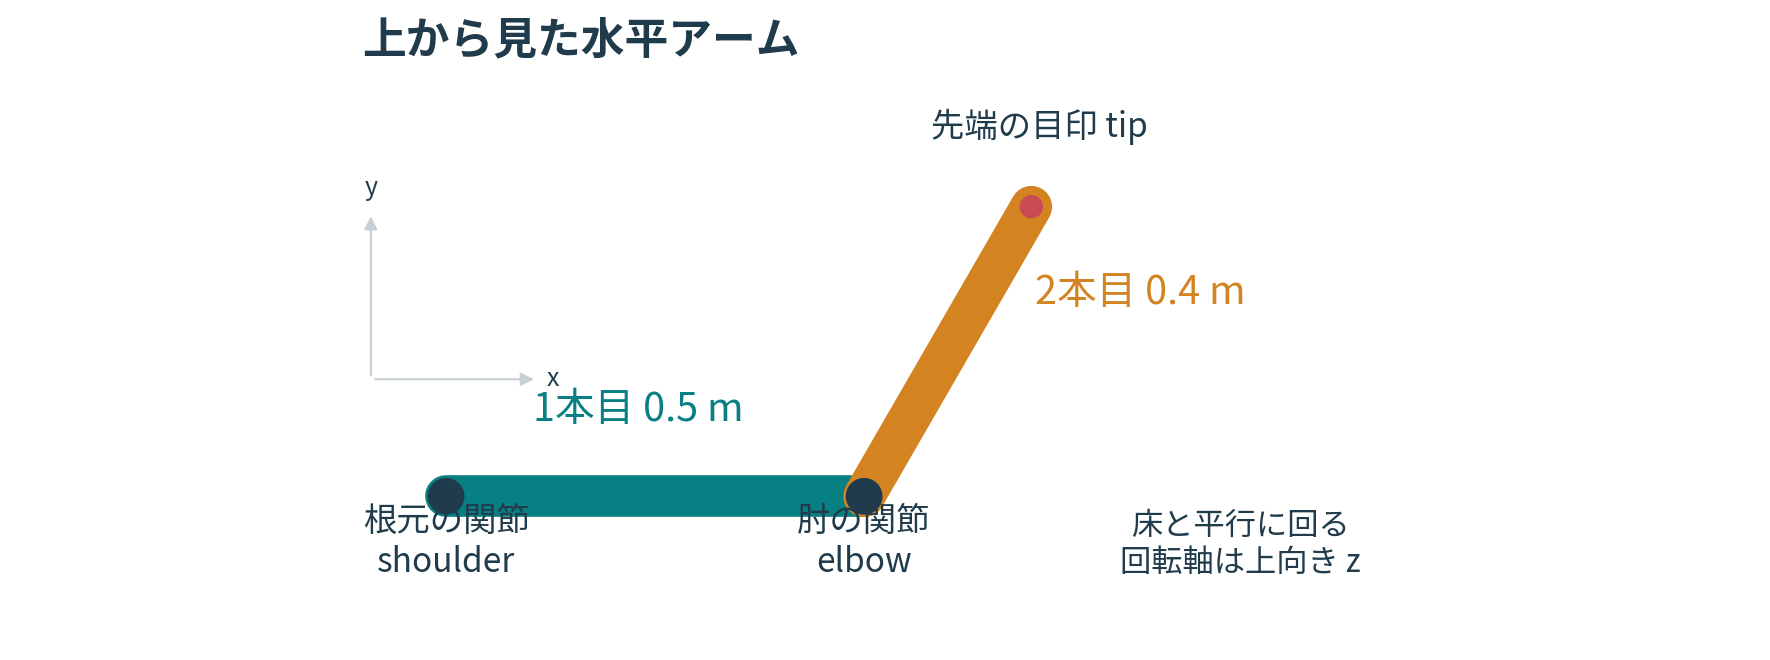

2本の棒を2つの回る関節でつなぎます。青緑が1本目、橙が2本目。**この装置を作り、姿勢を確かめてから、力で動かします。**

ここは上から見た水平アームです。小球の上下運動から場面が変わります。

### 全体の地図｜毎節、青緑の箱で現在地を確認する
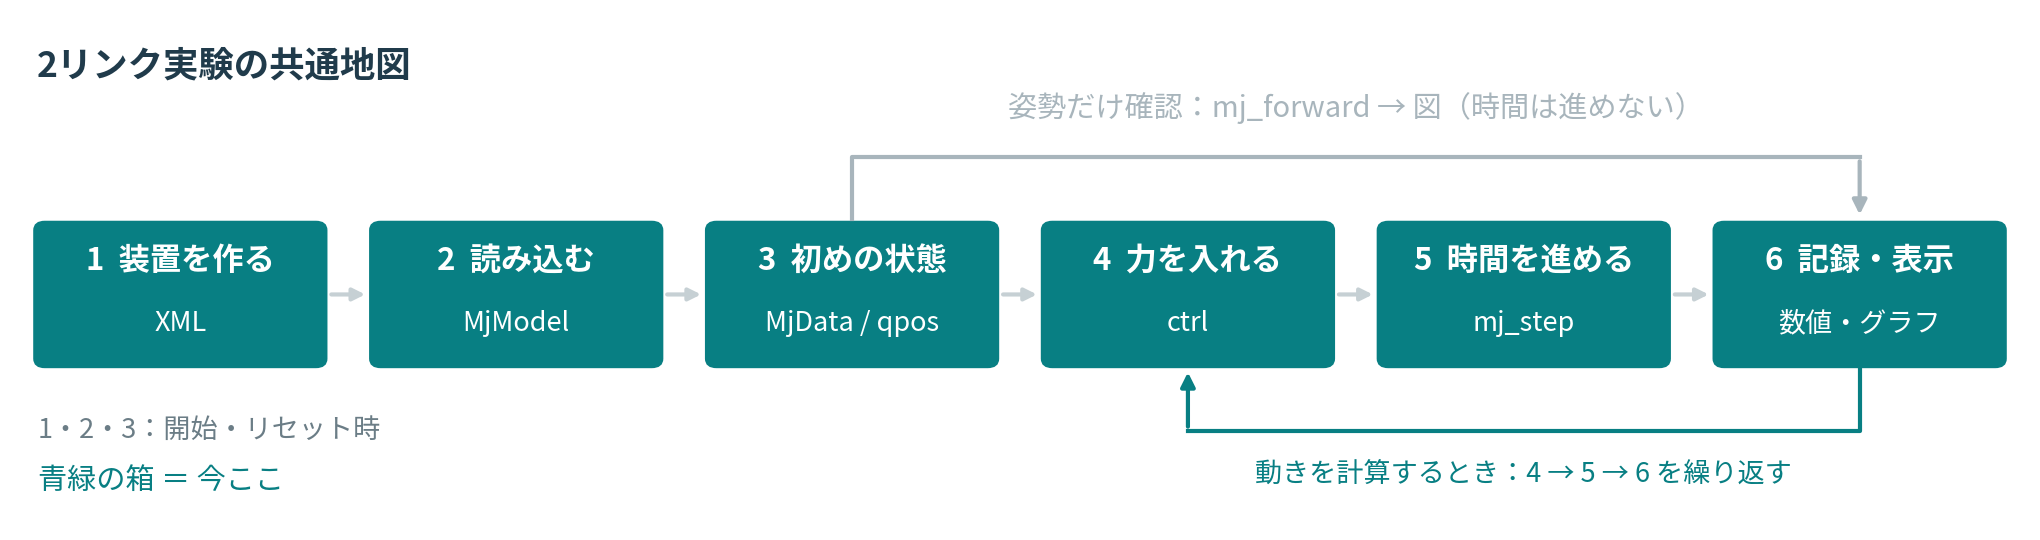

- **M5：作った形を確認。** ①②③の後、上の道で姿勢だけを表示します。時計は進めません。
- **M6：動きを計算。** ①②③の後、④⑤⑥を繰り返します。

①②③は実験の開始・やり直しのときに行います。④⑤⑥の繰り返し中に毎回dataを作り直すと、状態が最初に戻ってしまいます。

図の英語名はコードの目印です。まず「何をする箱か」を読みます。

**予想：** 動画にするには、同じ姿勢を表示するだけで十分？ 理由：＿＿

### 実行準備｜このNotebookの道具を用意する
次の3セルはライブラリ・MuJoCo・描画の準備です。順番に実行してください。初回は数分かかる場合があります。CPUで実行できます。

必要なXMLとPythonの道具は、このNotebook内にあります。ファイルの手動アップロードは不要です。

In [1]:
#@title 準備と表示用コード（実行してから折りたたんでよい）
import sys, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle
from IPython.display import display, HTML
get_ipython().run_line_magic('matplotlib', 'inline')
WORK = Path.cwd() / 'b3_lesson03B_2link'
WORK.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 12})
mission_status = {}


print("2リンク篇の準備フォルダ：", WORK)

2リンク篇の準備フォルダ： /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/robot-student/b3_lesson03B_2link


In [2]:
#@title MuJoCoのインストールと描画設定
import os, importlib.util, importlib.metadata, subprocess, ctypes.util
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    if ctypes.util.find_library('OSMesa') is None:
        subprocess.run(['apt-get', '-qq', 'update'], check=True)
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'libosmesa6'], check=True)
    os.environ['MUJOCO_GL'] = 'osmesa'
else:
    os.environ.setdefault('MUJOCO_GL', 'egl')
if importlib.util.find_spec('mujoco') is None or importlib.metadata.version('mujoco') != '3.3.3':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mujoco==3.3.3'], check=True)
import mujoco
print('MuJoCo', mujoco.__version__, '描画方式', os.environ['MUJOCO_GL'])

MuJoCo 3.3.3 描画方式 egl


In [3]:
#@title 3D表示の道具：計算済みqposを再生する
def render_qpos_log(xml, qpos_log, name, lookat, distance, elevation=-25, azimuth=90):
    m = mujoco.MjModel.from_xml_string(xml)
    m.vis.headlight.ambient[:] = [0.6, 0.6, 0.6]
    m.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
    d = mujoco.MjData(m)
    camera = mujoco.MjvCamera()
    camera.lookat[:] = lookat
    camera.distance, camera.elevation, camera.azimuth = distance, elevation, azimuth
    indices = np.unique(np.linspace(0, len(qpos_log)-1, min(40, len(qpos_log))).astype(int))
    frames = []
    with mujoco.Renderer(m, height=320, width=480) as renderer:
        for i in indices:
            d.qpos[:] = np.asarray(qpos_log[i])
            mujoco.mj_forward(m, d)
            renderer.update_scene(d, camera=camera)
            frames.append(renderer.render().copy())
    plt.imsave(WORK / f'{name}_first.png', frames[0])
    plt.imsave(WORK / f'{name}_last.png', frames[-1])
    fig, ax = plt.subplots(figsize=(7.2, 4.8)); ax.axis('off')
    picture = ax.imshow(frames[0])
    def update(i):
        picture.set_data(frames[i]); return (picture,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=70, blit=True)
    content = animation.to_jshtml(default_mode='once'); plt.close(fig)
    (WORK / f'{name}.html').write_text(content, encoding='utf-8')
    return HTML(content)

### M5.1｜① 装置を作る：まず1本の棒

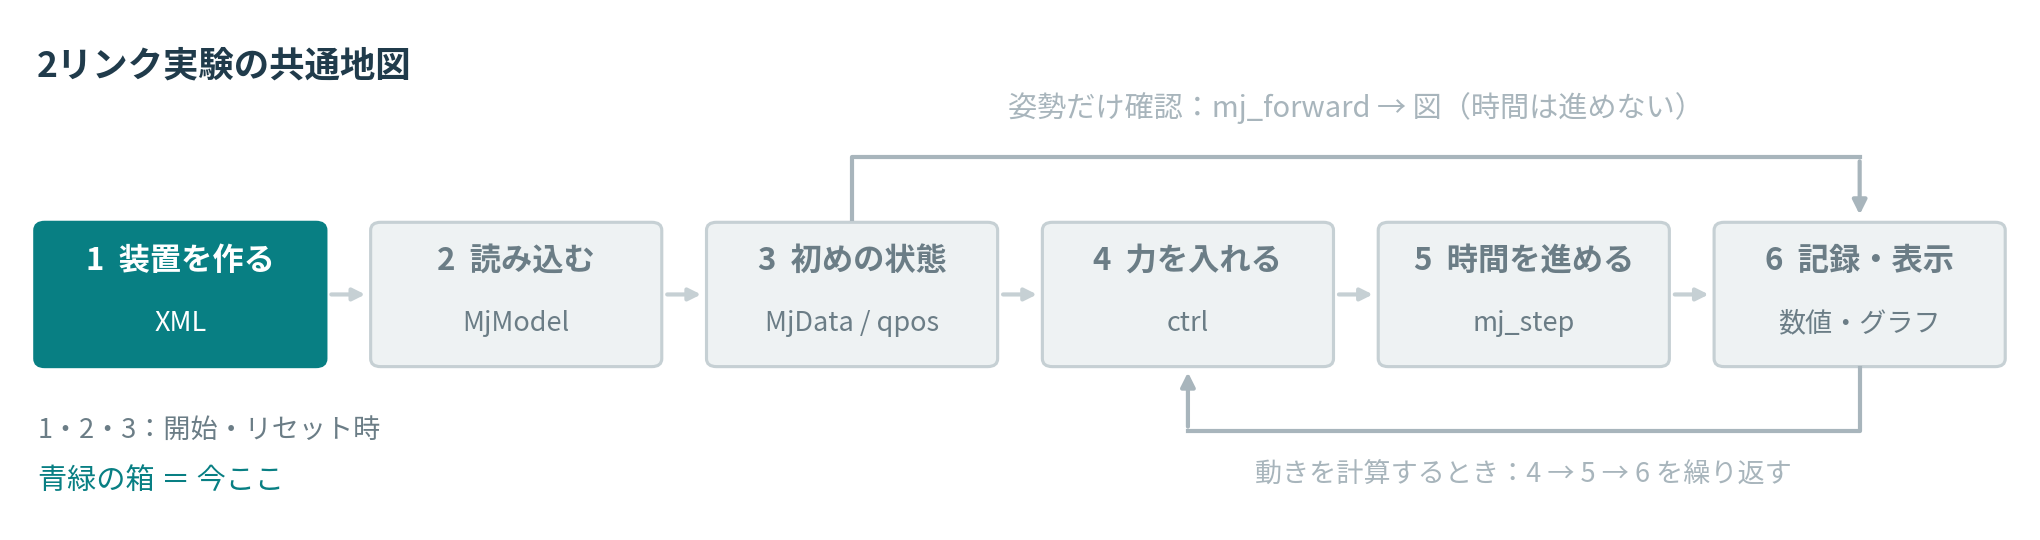

**今すること：** 長さ0.5 mの棒と、根元の回転関節を書く。

`body`＝一緒に動く部品、`joint`＝つなぎ方、`geom`＝形。棒の部品を**リンク**と呼びます。
`fromto="0 0 0 0.5 0 0"` は棒の両端です。下の5行で、長さに対応する数を見つけます。

In [4]:
LINK1 = """<body name="link1" pos="0 0 0.1">
  <joint name="shoulder" type="hinge" axis="0 0 1"/>
  <geom type="capsule" fromto="0 0 0 0.5 0 0" size="0.025" mass="0.3" rgba="0.14 0.49 0.48 1"/>
  <!-- child link -->
</body>"""

### M5.2｜① 共通の実験環境を付ける

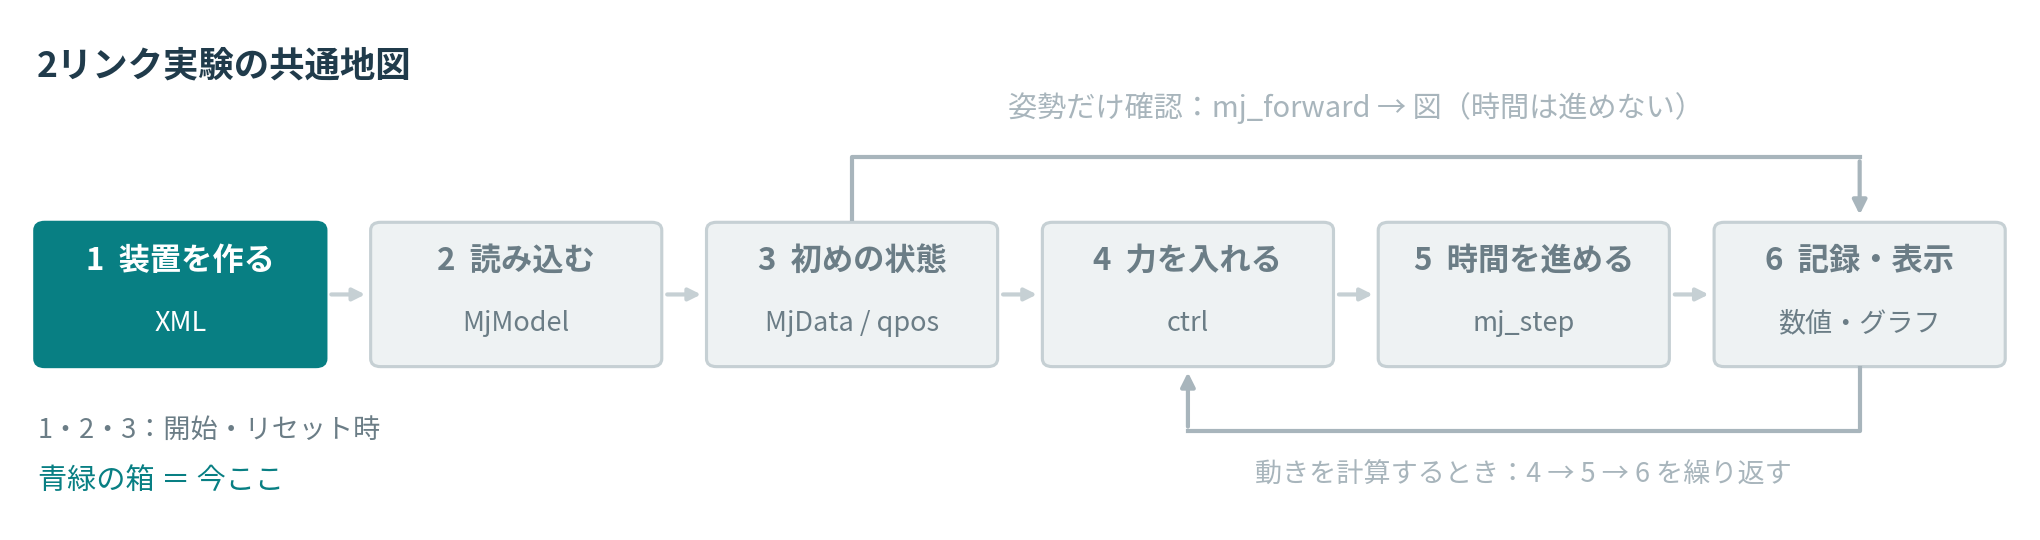

次の配布道具は、棒の説明に重力・時間刻み・床表示を付けます。
**入力は部品のXML、出力は装置全体のXML。** まだ時間は進めません。

接触は無効にして、棒のつながりに集中します。今の課題はこの道具の自作ではありません。

In [5]:
#@title アーム用XMLの共通の枠
def arm_scene(bodies, actuators=""):
    return f"""<mujoco>
      <option timestep="0.002" gravity="0 0 -9.81" integrator="implicitfast"/>
      <default><joint damping="0.1"/><geom contype="0" conaffinity="0"/></default>
      <worldbody><light pos="0 -2 3"/>
        <geom type="plane" size="1.4 1.4 0.1" rgba="0.85 0.86 0.84 1"/>
        {bodies}
      </worldbody>{actuators}
    </mujoco>"""

### M5.3｜① 2本目を先端につなぐ

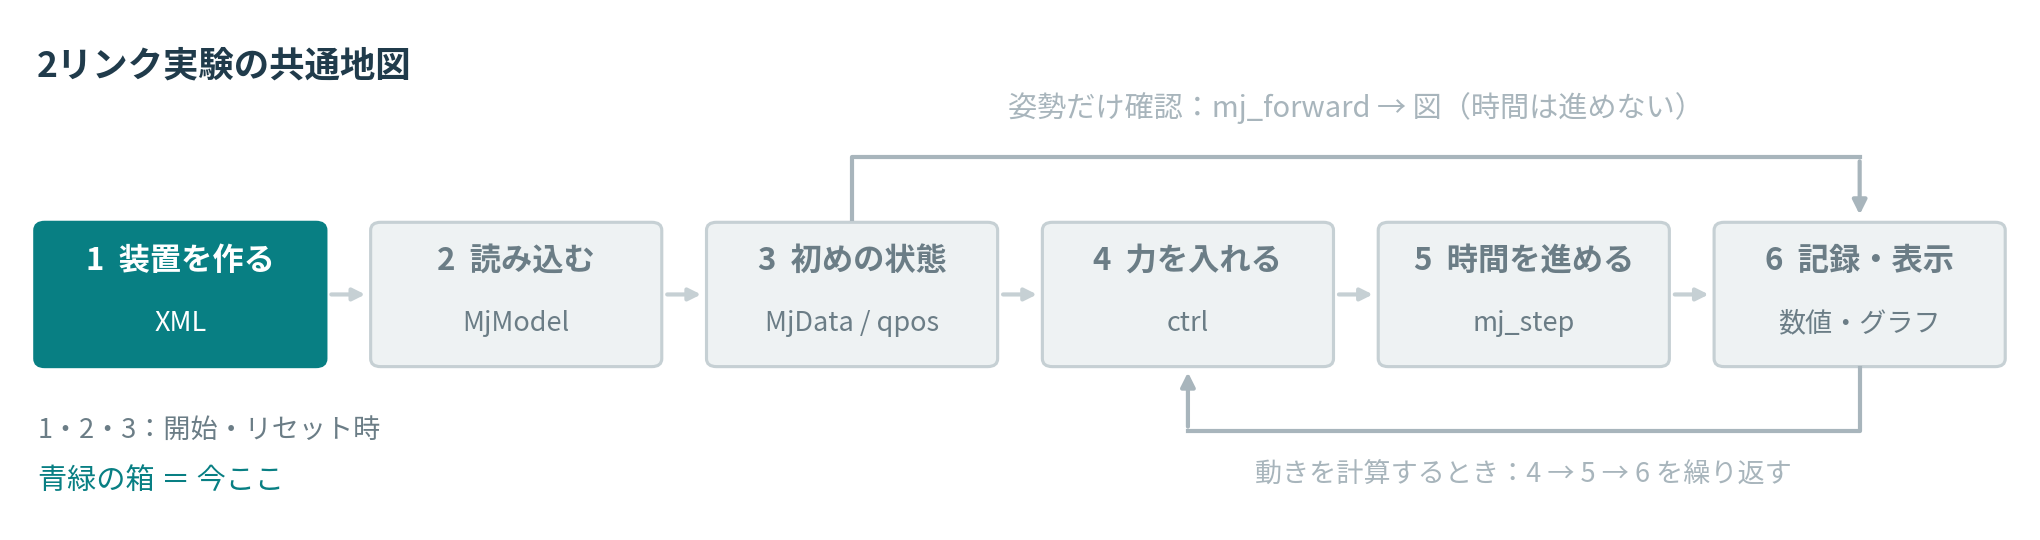

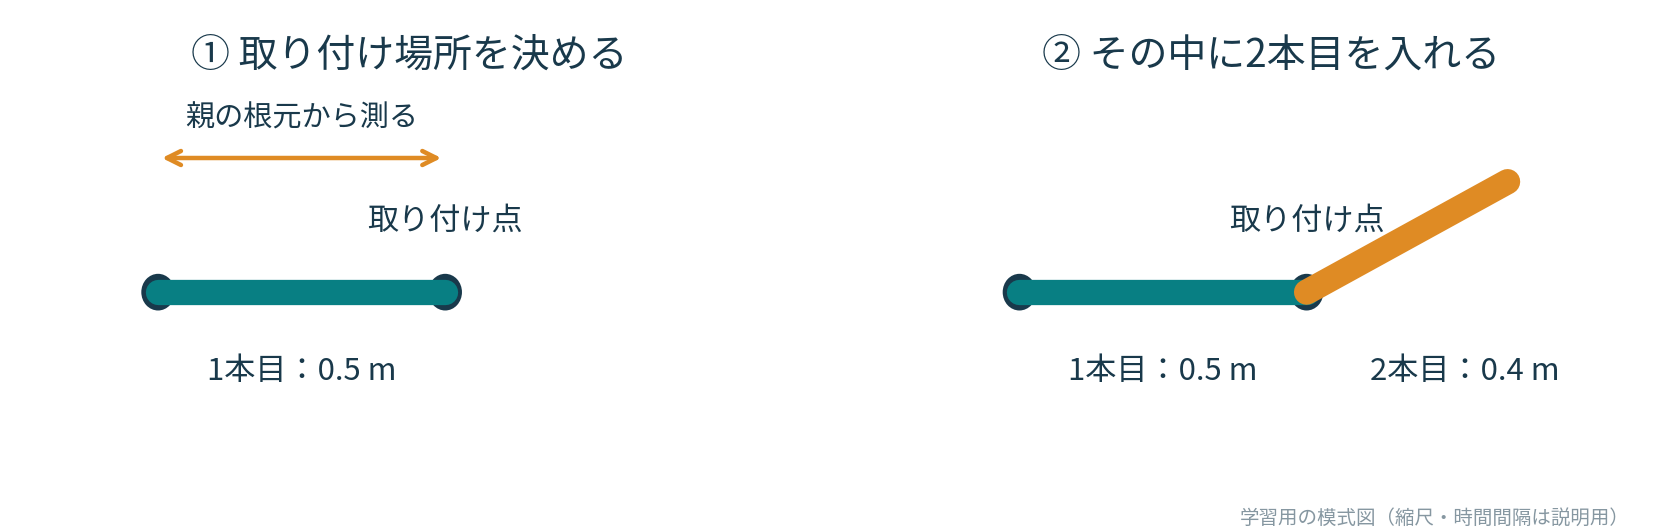

**自分で書くM5a：** `child_mount` の3つの数を直します。位置は**1本目の根元から**測ります。初期値では根元に重なります。

`site name="tip"` は2本目の先端を読む目印。質量や接触を追加する物体ではありません。

**予想：** 2本目をどこに取り付ける？ 数と理由：＿＿

In [6]:
child_mount = "0 0 0"  # TODO: 親link1の先端の座標
LINK2 = f"""<body name="link2" pos="{child_mount}">
  <joint name="elbow" type="hinge" axis="0 0 1"/>
  <geom type="capsule" fromto="0 0 0 0.4 0 0" size="0.02" mass="0.2" rgba="0.78 0.39 0.24 1"/>
  <site name="tip" pos="0.4 0 0" size="0.025"/>
</body>"""
TWO_LINKS = LINK1.replace("<!-- child link -->", LINK2)
ARM_POSE_XML = arm_scene(TWO_LINKS)

### M5.4｜② 説明文を、計算用の装置にする

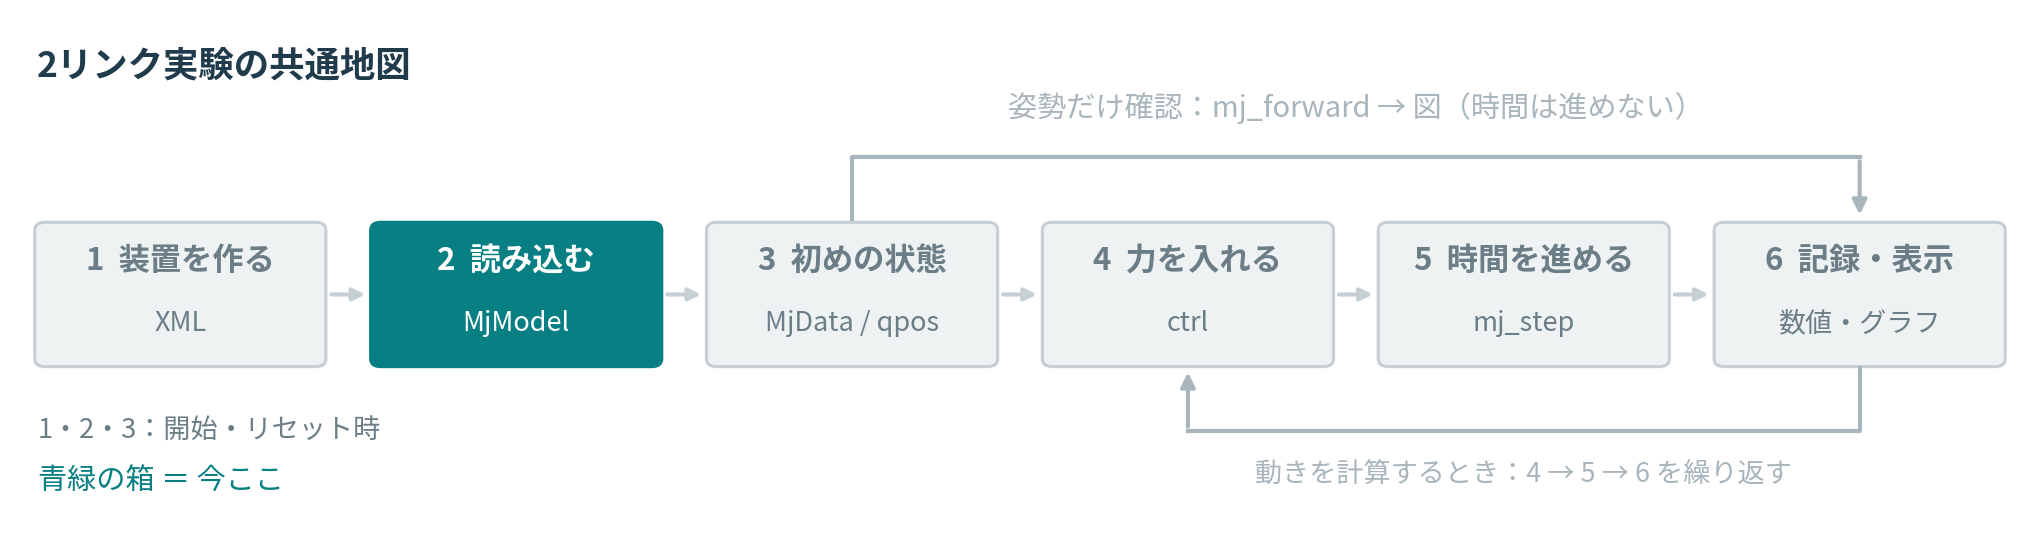

**今すること：** XMLをMuJoCoへ読み込む。
1行目は1本用、2行目は自分でつないだ2本用です。`model` に装置の情報が入ります。

**確認：** `nv` が1本では1、2本では2かを見ます。時間を進める行はまだありません。

In [7]:
single_model = mujoco.MjModel.from_xml_string(arm_scene(LINK1))
arm_model = mujoco.MjModel.from_xml_string(ARM_POSE_XML)
print("回転できる関節の数:", single_model.nv, arm_model.nv)

回転できる関節の数: 1 2


### M5.5｜③ 最初の姿勢を指定する

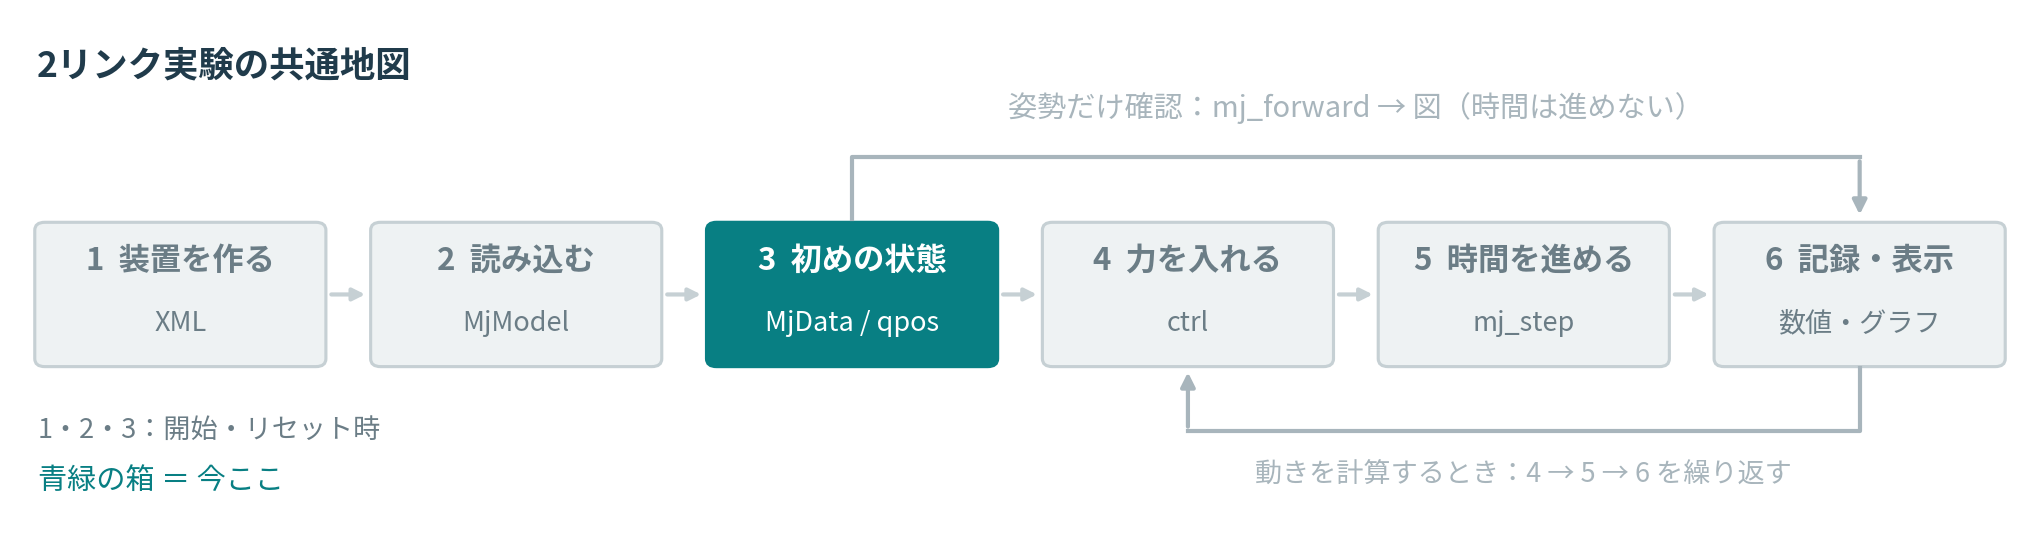

**今すること：** まず1本の棒を90°に置く。

`MjData` はこの装置の今の状態。`qpos` は関節角度です。実行時の角度はradなので、`np.deg2rad(90)` で変換します。

$$q_{\mathrm{rad}}=q_{\mathrm{deg}}\pi/180.$$

**予想：** 90°に置いた棒は図のどちらを向く？ ＿＿

In [8]:
single_data = mujoco.MjData(single_model)
single_data.qpos[0] = np.deg2rad(90)

### M5.6｜上の道：今の姿勢の位置関係を更新する

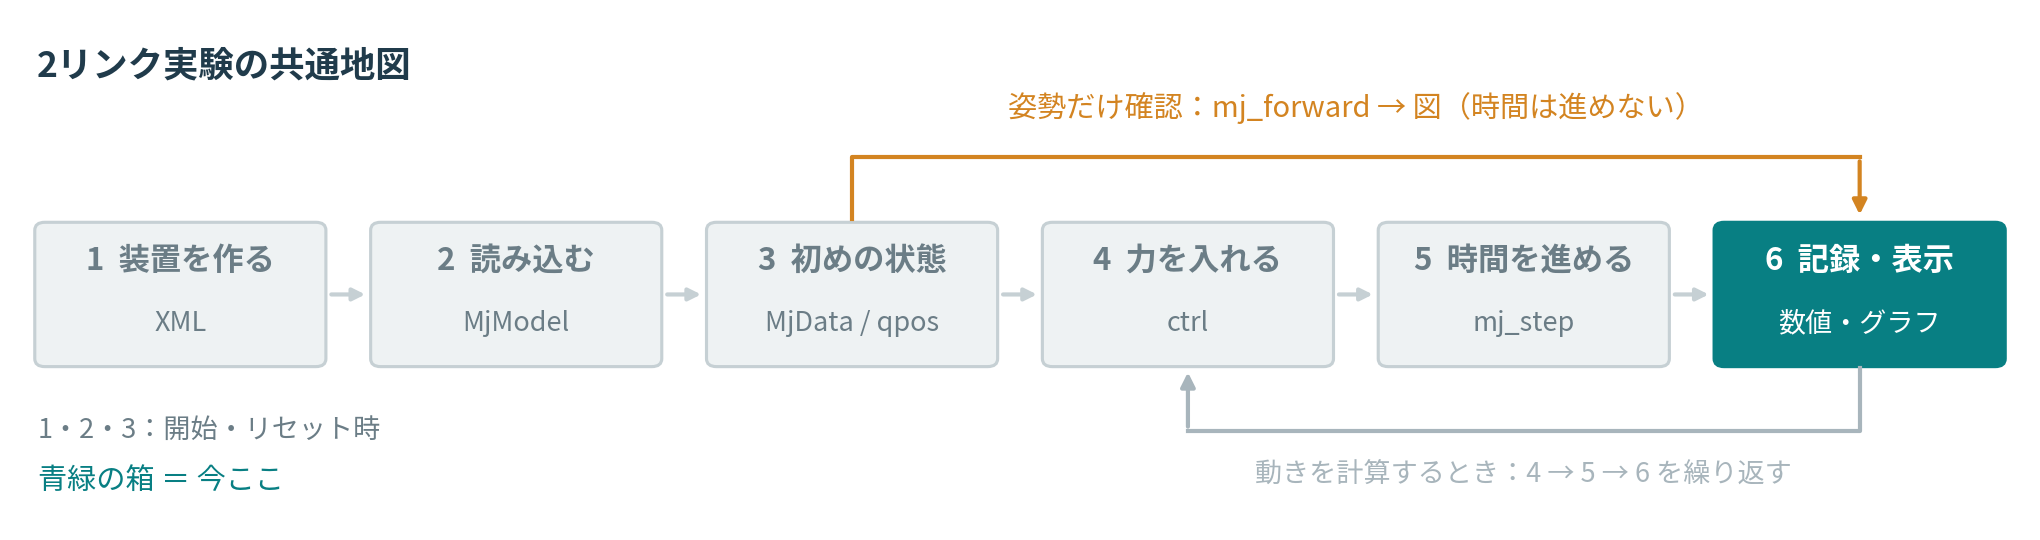

**今すること：** 指定した角度から、棒や先端の位置を計算する。

`mj_forward` は時計を進めません。ここでは図の上の道を通り、④力と⑤時間更新を使いません。

**確認：** 出力の時刻は0のまま？ ＿＿

In [9]:
mujoco.mj_forward(single_model, single_data)
print("角度 [rad]:", single_data.qpos, "時刻:", single_data.time)

角度 [rad]: [1.57079633] 時刻: 0.0


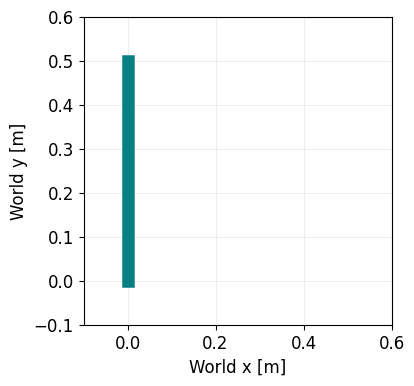

In [10]:
#@title 1本の棒を上から見る（位置データから描画）
base = single_data.body("link1").xpos.copy()
rotation = single_data.body("link1").xmat.reshape(3, 3)
end = base + rotation @ np.array([0.5, 0., 0.])
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([base[0], end[0]], [base[1], end[1]], "o-", color="#087f83", lw=9)
ax.set(xlim=(-.1,.6), ylim=(-.1,.6), xlabel="World x [m]", ylabel="World y [m]")
ax.set_aspect("equal"); ax.grid(alpha=.2); plt.show()

### M5.7｜③ → 上の道：2関節の姿勢を自分で作る

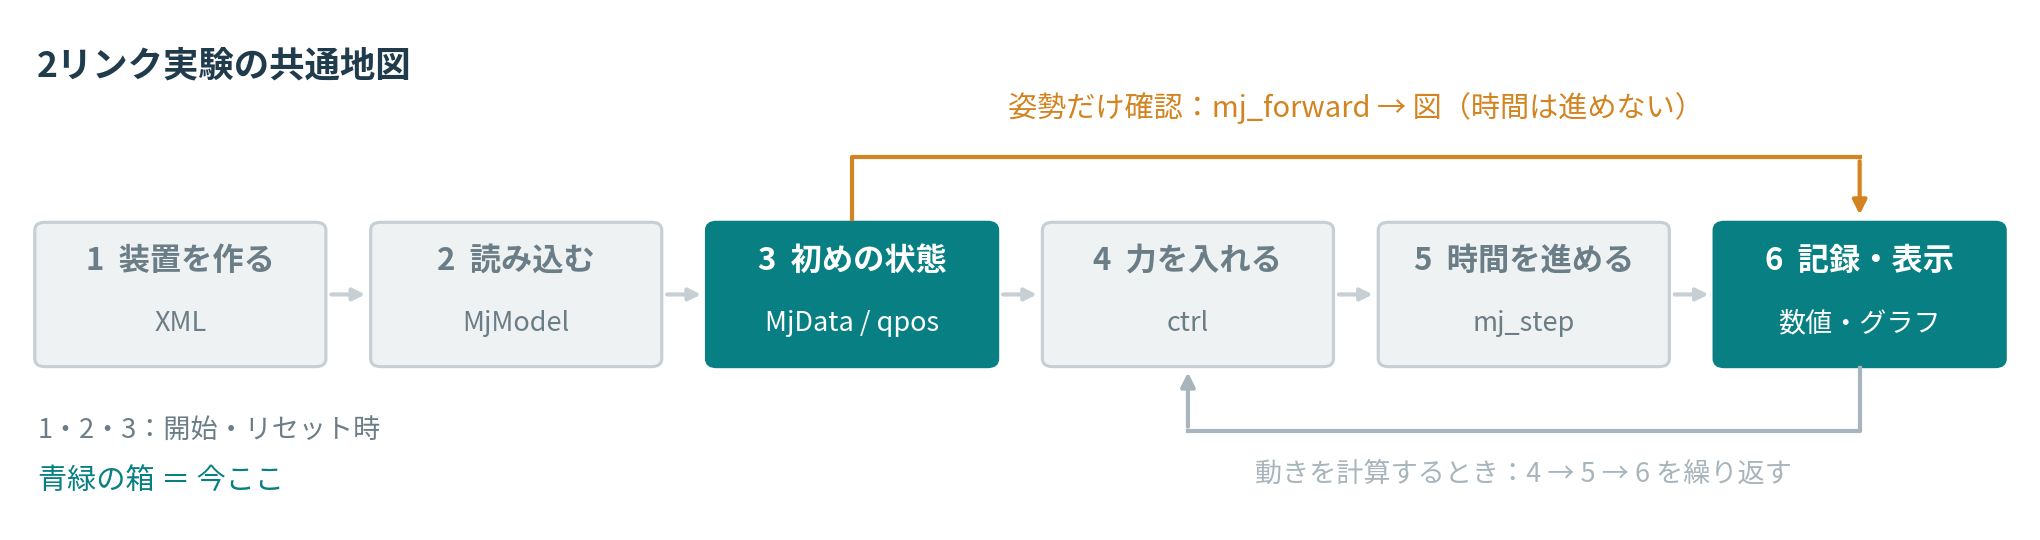

**自分で書くM5b：** 1本の例を2本へ広げます。`pass` を2行に置き換えます。

1. `np.deg2rad([q1_deg, q2_deg])` を `d.qpos[:]` へ入れる。
2. 今の位置関係を更新する行を書く。

順番は**肩、肘**。肘は1本目に対する角度です。`[:]` は配列全体に入れる記法です。

In [11]:
def set_arm_pose(model, q1_deg, q2_deg):
    d = mujoco.MjData(model)
    pass  # TODO: qposにradの角度を入れ、位置を更新（2行）
    return d

### M5.8｜⑥ 結果を見て、つながりを確かめる

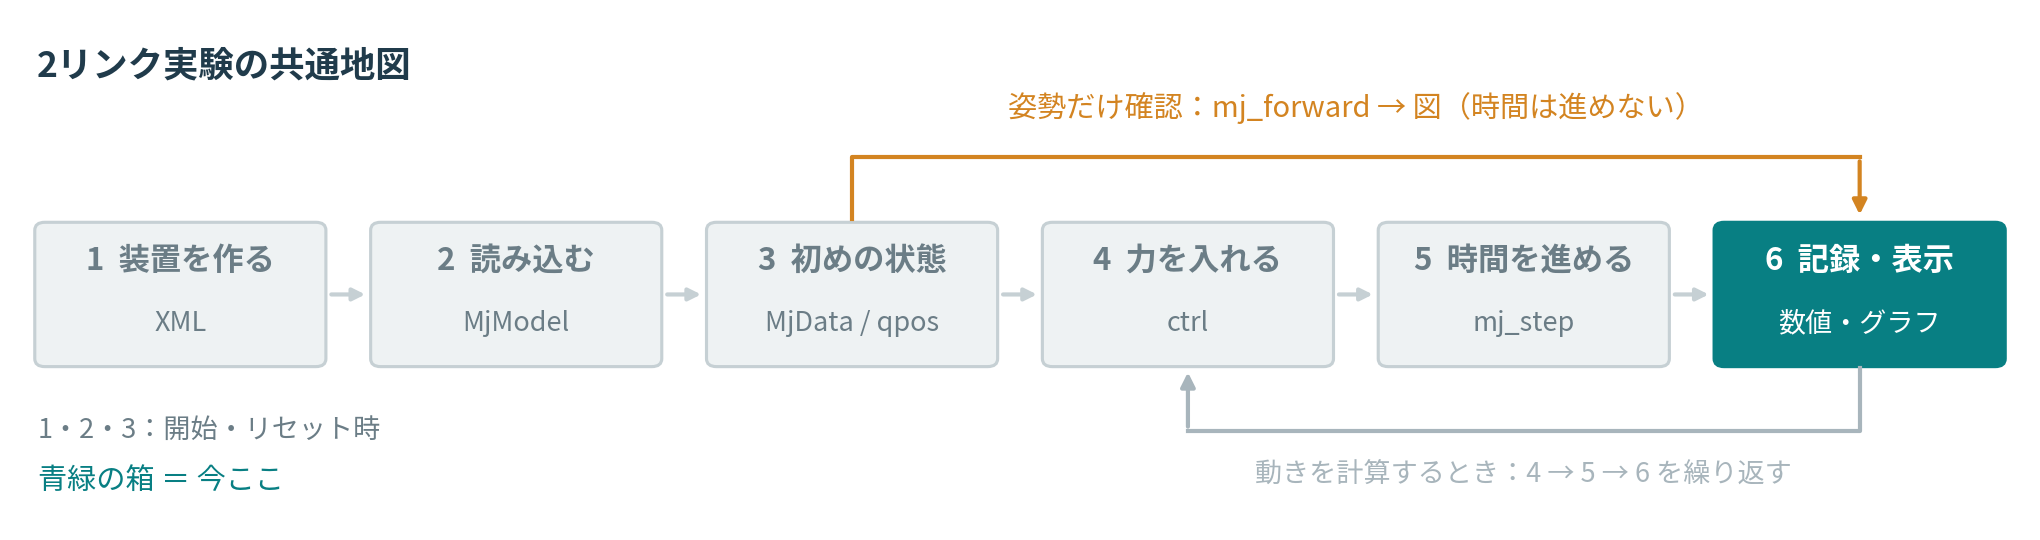

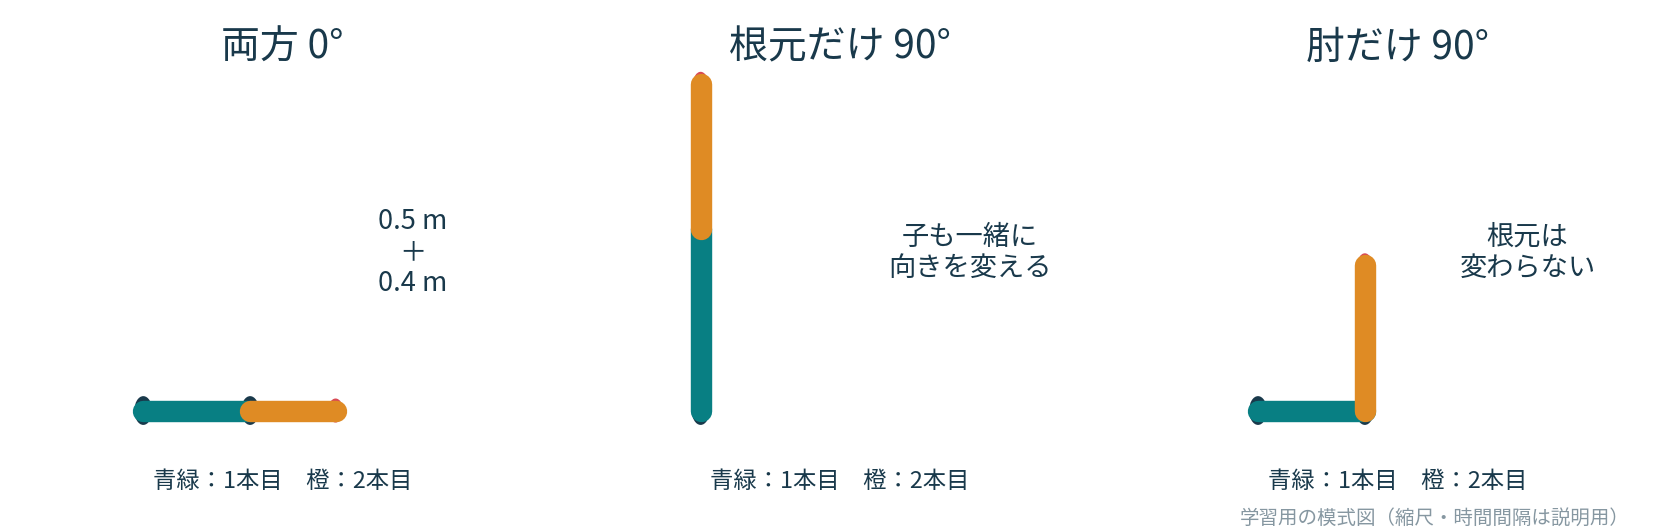

**見る場所：** 肩だけ90°にした場合と、肘だけ90°にした場合の肘の位置。

図は上から見た模式図です。下の道具で自分の計算と比べます。この平面アームで2本目の向きは $q_1+q_2$。親を回すと子も一緒に向きを変えます。

In [12]:
#@title 上から見たアームの表示道具
def plot_arm(points, name, show_target=True):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(points[:2,0], points[:2,1], 'o-', lw=7, color='#247c7a', label='Link 1')
    ax.plot(points[1:,0], points[1:,1], 'o-', lw=7, color='#c9633d', label='Link 2')
    if show_target:
        ax.add_patch(Circle((0.45, 0.60), 0.04, color='#c9633d', alpha=0.25))
        ax.plot(0.45, 0.60, 'x', color='black', label='Target')
    ax.set(xlim=(-1.0, 1.0), ylim=(-1.0, 1.0), xlabel='World x [m]', ylabel='World y [m]')
    ax.set_aspect('equal'); ax.legend(loc='lower left')
    fig.tight_layout(); fig.savefig(WORK/f'{name}.png', dpi=140); plt.show()

In [13]:
#@title 接続と姿勢の確認道具
def arm_points(d):
    return np.vstack([d.body("link1").xpos.copy(), d.body("link2").xpos.copy(), d.site("tip").xpos.copy()])

def check_arm(model, fn, verbose=True):
    try:
        ok = model.nq == 2
        cases = [(0,0,[.5,0],[.9,0]), (90,0,[0,.5],[0,.9]), (0,90,[.5,0],[.5,.4])]
        for q1, q2, elbow, tip in cases:
            d = fn(model, q1, q2); points = arm_points(d)
            ok = (ok and d.time == 0 and np.allclose(d.qpos, np.deg2rad([q1,q2]))
                  and np.allclose(points[1,:2], elbow) and np.allclose(points[2,:2], tip))
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M5 コード確認:", "PASS" if ok else "未完成／再確認（接続位置・rad・forwardを確認）")
    return bool(ok)
arm_ready = check_arm(arm_model, set_arm_pose)
if arm_ready:
    for q1, q2 in [(0,0), (90,0), (0,90)]:
        pose = set_arm_pose(arm_model, q1, q2)
        print("角度 [deg]:", q1, q2, "肘・先端xy:", arm_points(pose)[1:,:2])
    plot_arm(arm_points(set_arm_pose(arm_model, 30, 60)), "arm_pose_example")
else:
    print("M5aとM5bを完成後、この確認セルも実行し直します。")

M5 コード確認: 未完成／再確認（接続位置・rad・forwardを確認）
M5aとM5bを完成後、この確認セルも実行し直します。


### M5.9｜③ → 上の道 → ⑥：先端を目標へ置く

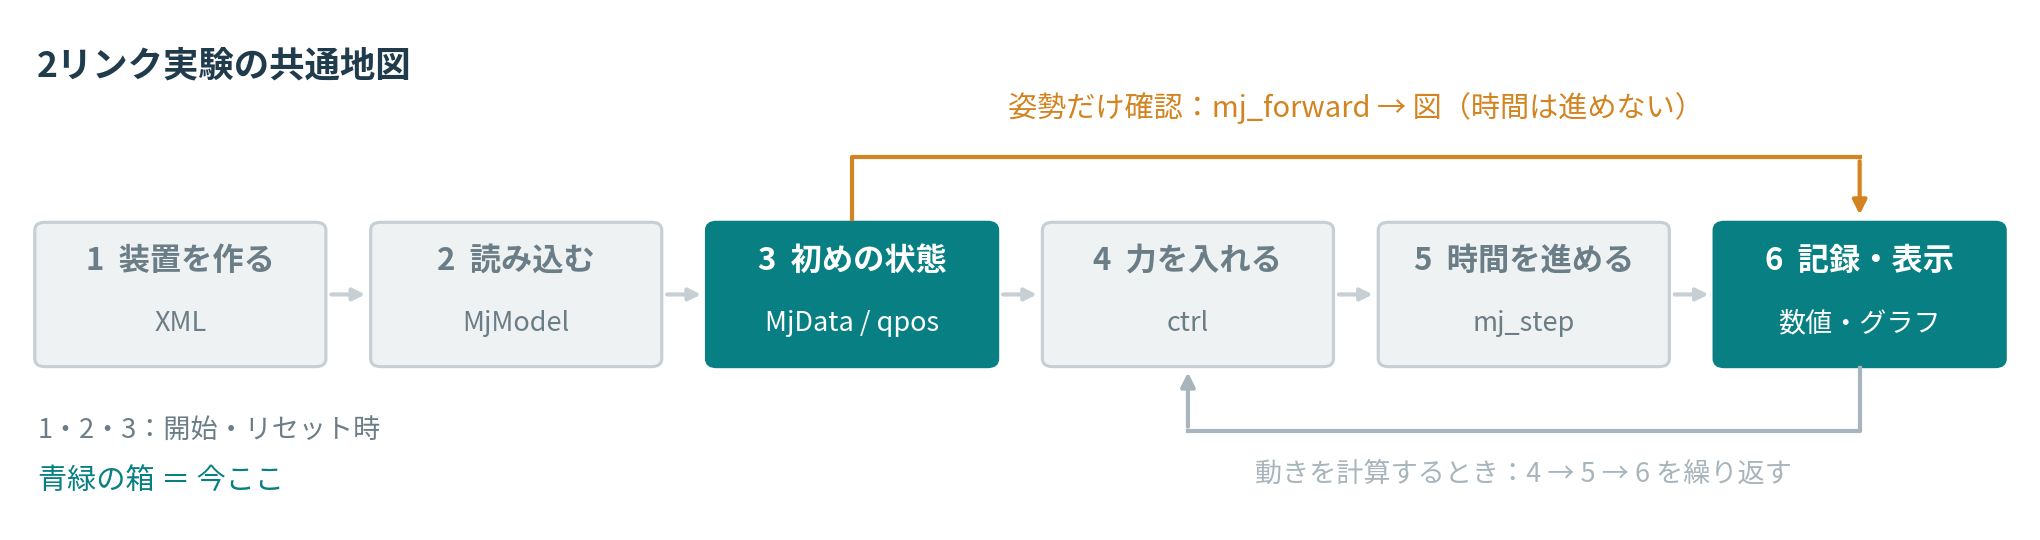

目標は(x,y)=(0.45,0.60) m、半径0.04 mです。角度を選び、2回以上試します。

**記録すること：** 肩・肘の角度 → 目標との距離 → 次に変える理由。

これは**姿勢を選ぶ課題**です。力による運動は、次のM6で作ります。

In [14]:
target_q1, target_q2 = 0.0, 0.0  # TODO: 予想して角度を決める [deg]
target_error = None
if check_arm(arm_model, set_arm_pose, verbose=False):
    target_data = set_arm_pose(arm_model, target_q1, target_q2)
    target_points = arm_points(target_data)
    target_error = float(np.linalg.norm(target_points[-1,:2] - [.45,.60]))
    print("目標までの距離 [m]:", target_error, "到達:", target_error <= .04)
    plot_arm(target_points, "arm_target")
else:
    print("M5a/bの完成後に目標課題を実行します。")

M5a/bの完成後に目標課題を実行します。


### M5の回答｜流れ図を指して説明する

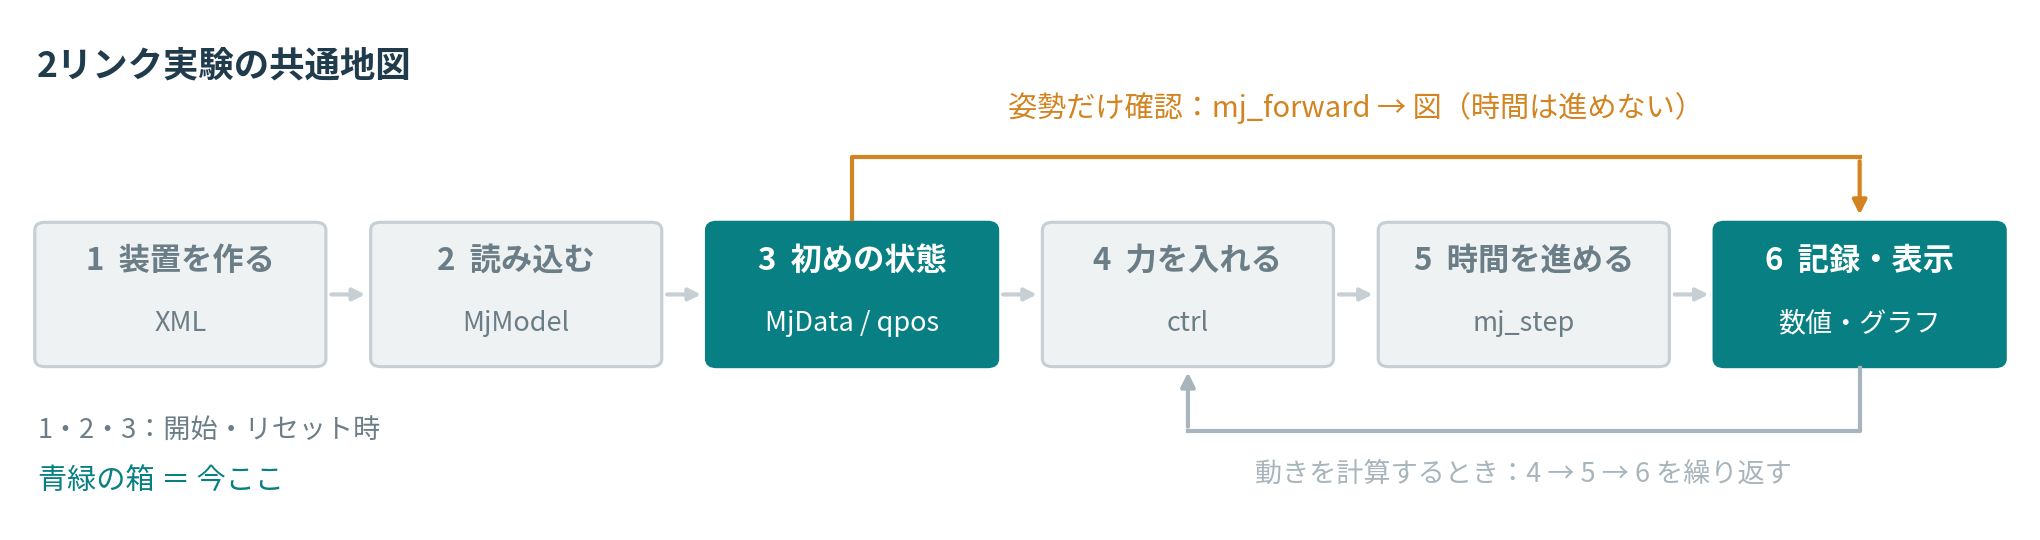

肩だけ90°の場合と肘だけ90°の場合の、肘の座標を記録してください。

**座標と理由：** ＿＿

`set_arm_pose` の自作2行は、地図のどこですか。時計を進めましたか。

**行と役割：** ＿＿

**目標への試行①（角度・距離・理由）：** ＿＿　**試行②：** ＿＿

## M6｜同じロボットを、今度は力で動かす
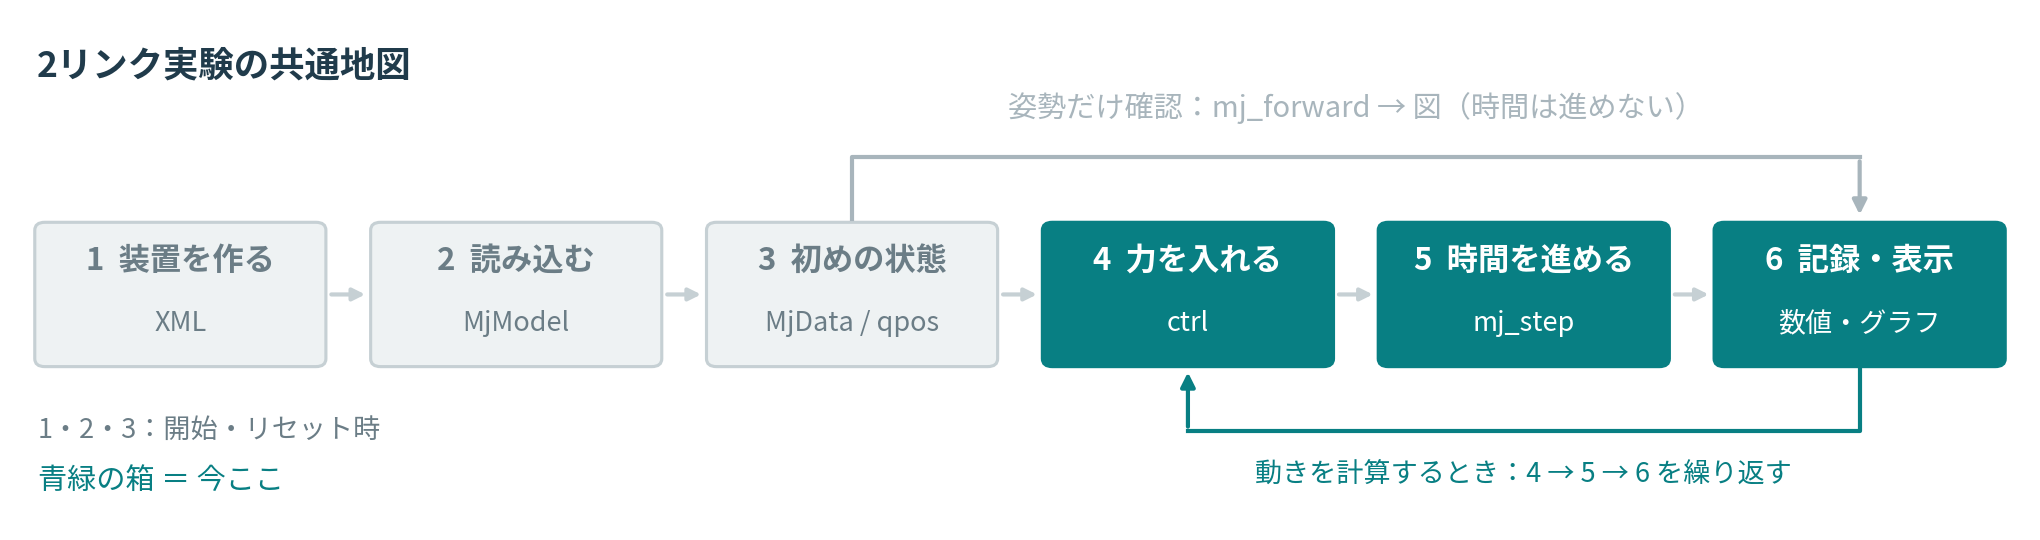

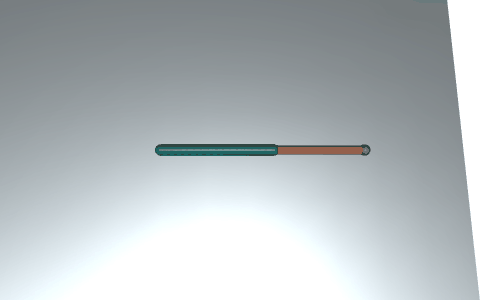

**先に見る配布例：** 肩へ短時間だけ回す力を入れています。この動画は、検証済みの例の計算結果です。自分の課題の完成とは別です。

今度は**④力 → ⑤時間 → ⑥記録**の道を使います。棒の角度がどう変わるかをMuJoCoに計算させます。

### M6.1｜① 装置に、回す力を入れる仕組みを足す

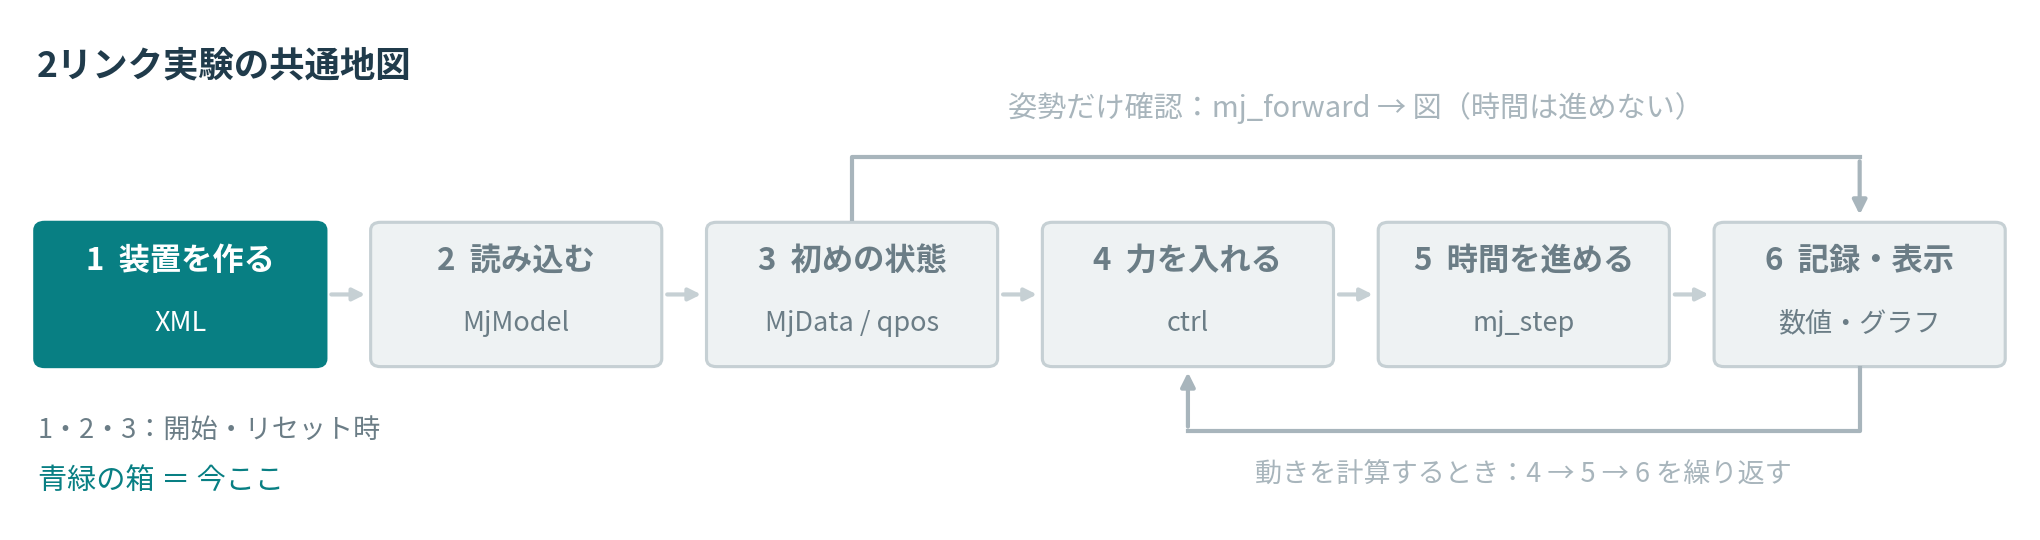

回す力を**トルク**、力を入れる仕組みをここでは **motor** と呼びます。

次の2つのmotorを、名前で肩と肘につなぎます。`joint="shoulder"` と `joint="elbow"` を探してください。

**予想：** 肩だけに力を入れたいとき、どちらを使う？ ＿＿

In [15]:
MOTORS = """<actuator>
  <motor name="shoulder_motor" joint="shoulder" gear="1" ctrllimited="true" ctrlrange="-1 1"/>
  <motor name="elbow_motor" joint="elbow" gear="1" ctrllimited="true" ctrlrange="-1 1"/>
</actuator>"""

### M6.2｜② 入力付きの装置を読み込む

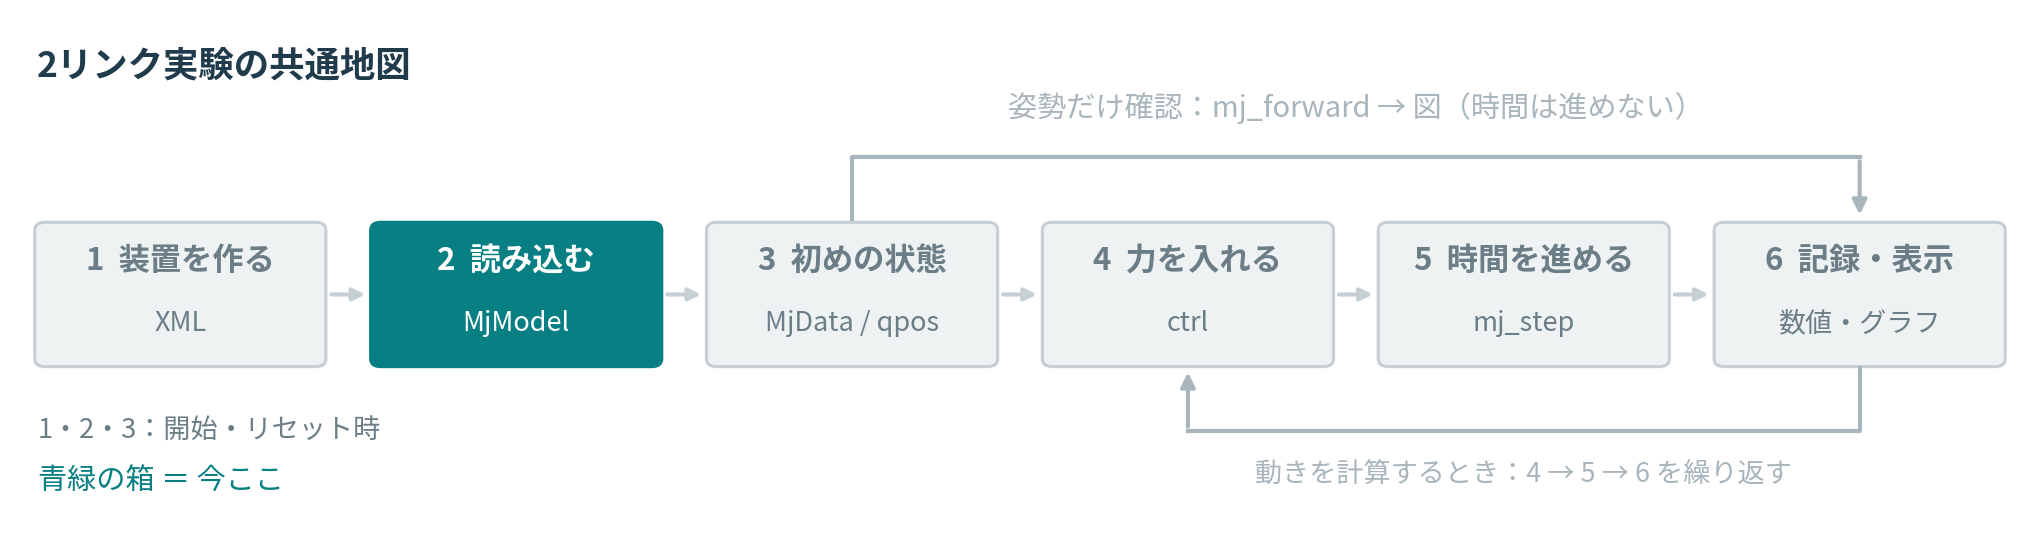

ここは正しく接続された配布モデルを使います。M5の自作課題は別に完成させてください。

今回のhinge用motorは `gear=1`。範囲内の入力をトルク **N·m** として扱います。下の道具で読み込みます。

In [16]:
#@title 入力練習用の接続済みモデル（M5の自作モデルとは別）
reference_link2 = """<body name="link2" pos="0.5 0 0">
  <joint name="elbow" type="hinge" axis="0 0 1"/>
  <geom type="capsule" fromto="0 0 0 0.4 0 0" size="0.02" mass="0.2" rgba="0.78 0.39 0.24 1"/>
  <site name="tip" pos="0.4 0 0" size="0.025"/>
</body>"""
DRIVE_XML = arm_scene(LINK1.replace("<!-- child link -->", reference_link2), MOTORS)
drive_model = mujoco.MjModel.from_xml_string(DRIVE_XML)
print("nq, nv, nu（入力の数） =", drive_model.nq, drive_model.nv, drive_model.nu)

nq, nv, nu（入力の数） = 2 2 2


### M6.3｜③ 最初の角度と速度を決める

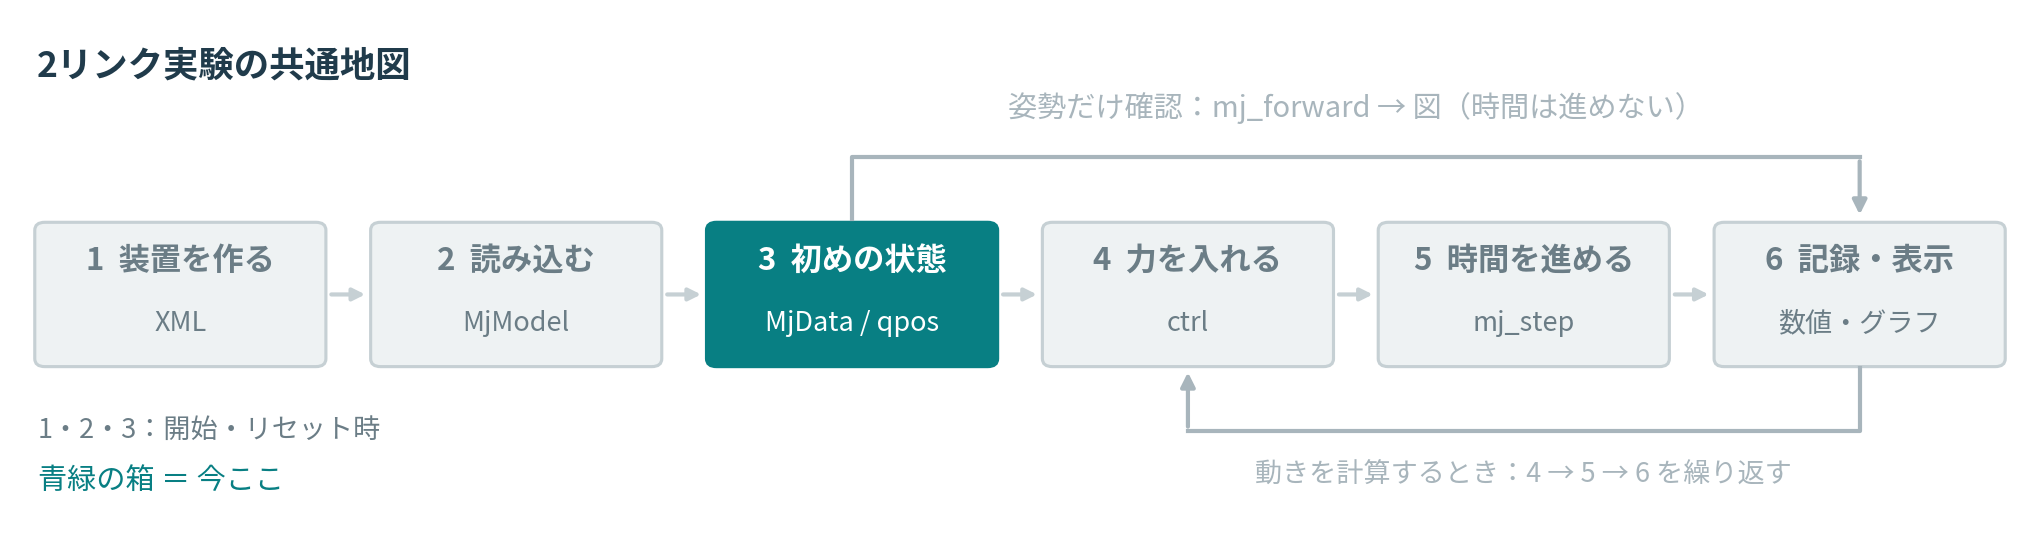

**今すること：** 新しい状態の入れ物を作り、2つの角度と2つの速度を0にする。

`qpos`＝角度[rad]、`qvel`＝角速度[rad/s]。この3行は初期条件です。

In [17]:
drive_example = mujoco.MjData(drive_model)
drive_example.qpos[:] = [0.0, 0.0]
drive_example.qvel[:] = [0.0, 0.0]

### M6.4｜④ 肩にだけ入力する

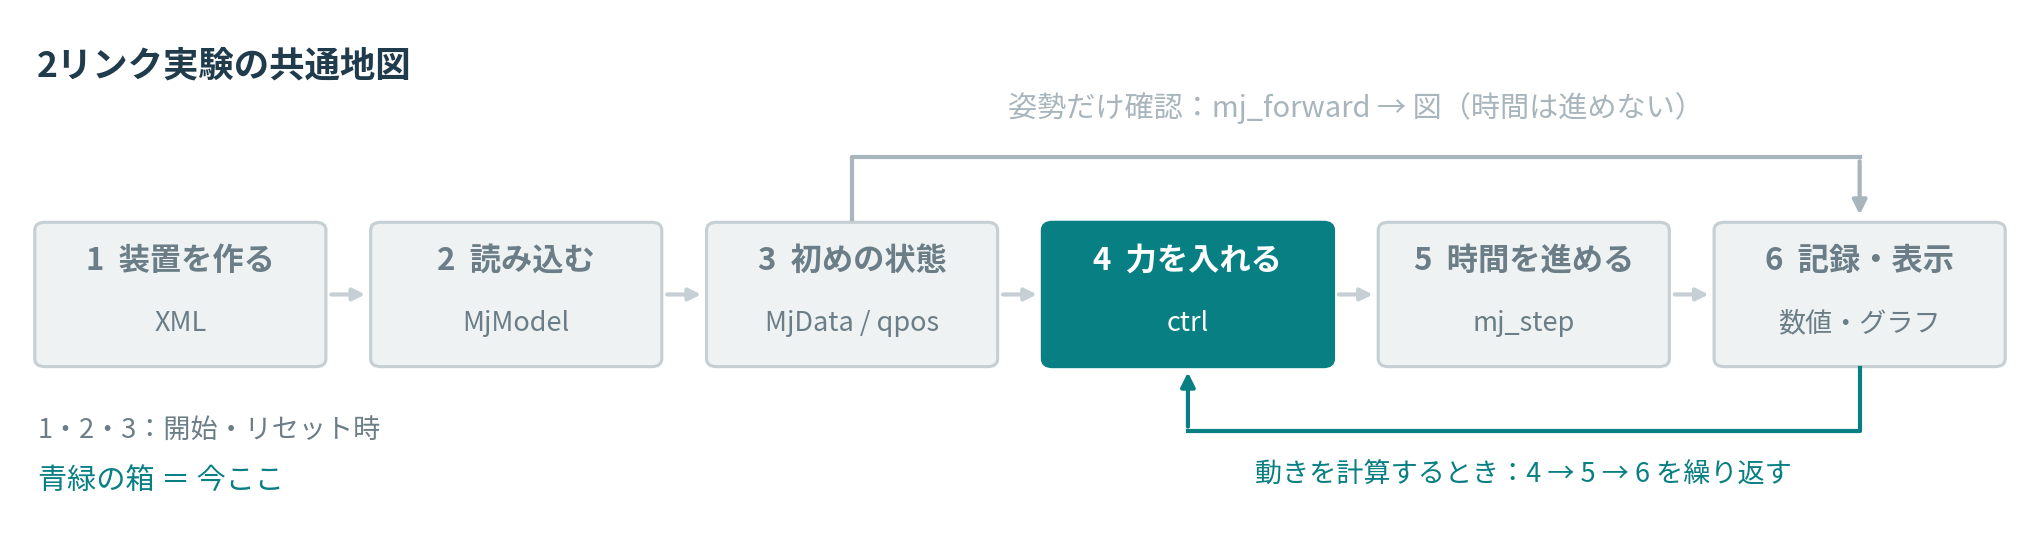

**今すること：** 肩へ0.2 N·m、肘へ0 N·mを入れる。

`ctrl` が入力の場所。配列の順番は肩、肘です。角度を指定する場所ではありません。

**予想：** 入力0の肘も動く？ ＿＿

In [18]:
drive_example.ctrl[:] = [0.2, 0.0]

### M6.5｜⑤ 時間を1刻み進める

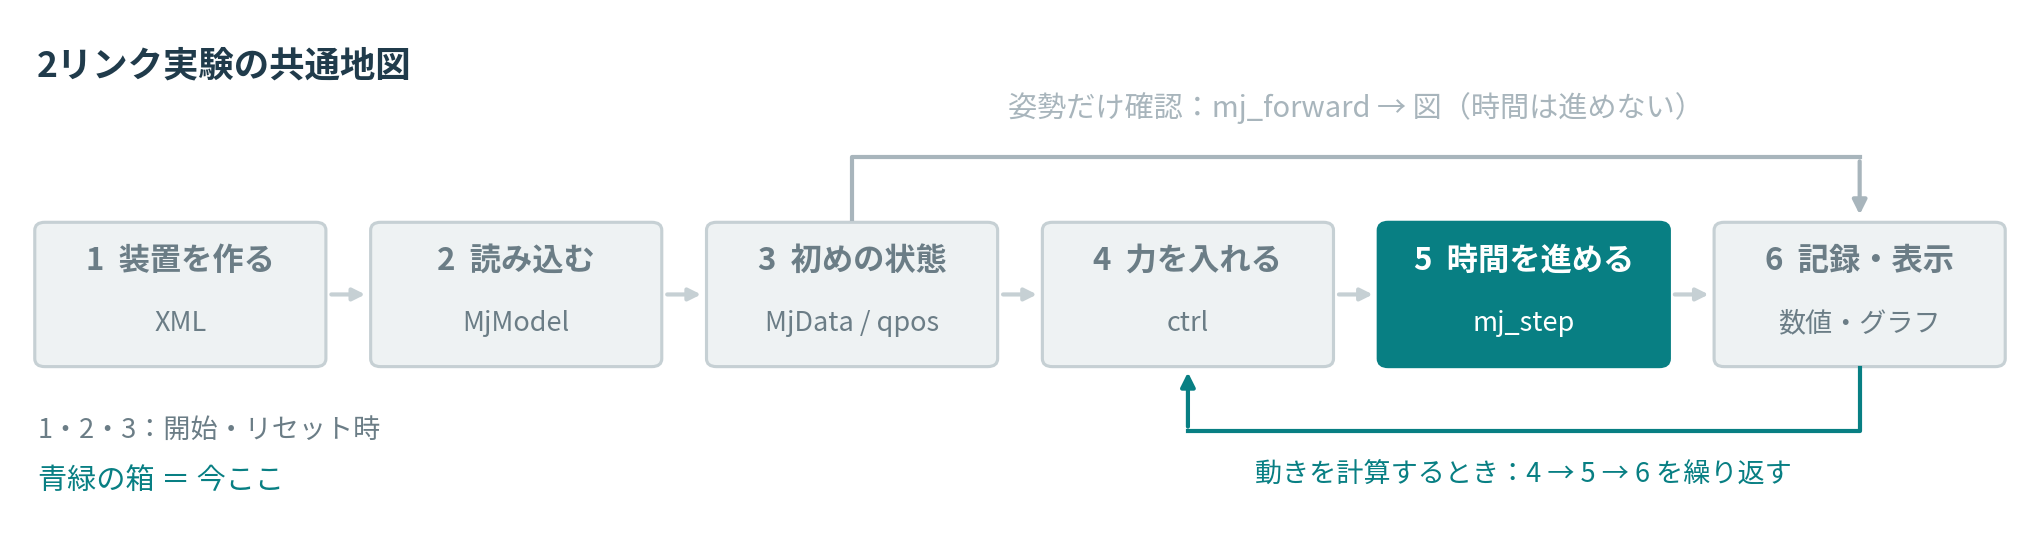

**今すること：** 今の状態と入力から、次の状態を計算する。

`mj_step` が動力学計算と時間更新を行います。今回の刻みは0.002秒。繰り返すと時刻は 0 → 0.002 → 0.004 秒と進みます。

In [19]:
mujoco.mj_step(drive_model, drive_example)

### M6.6｜⑥ 時刻・角度・速度を読む

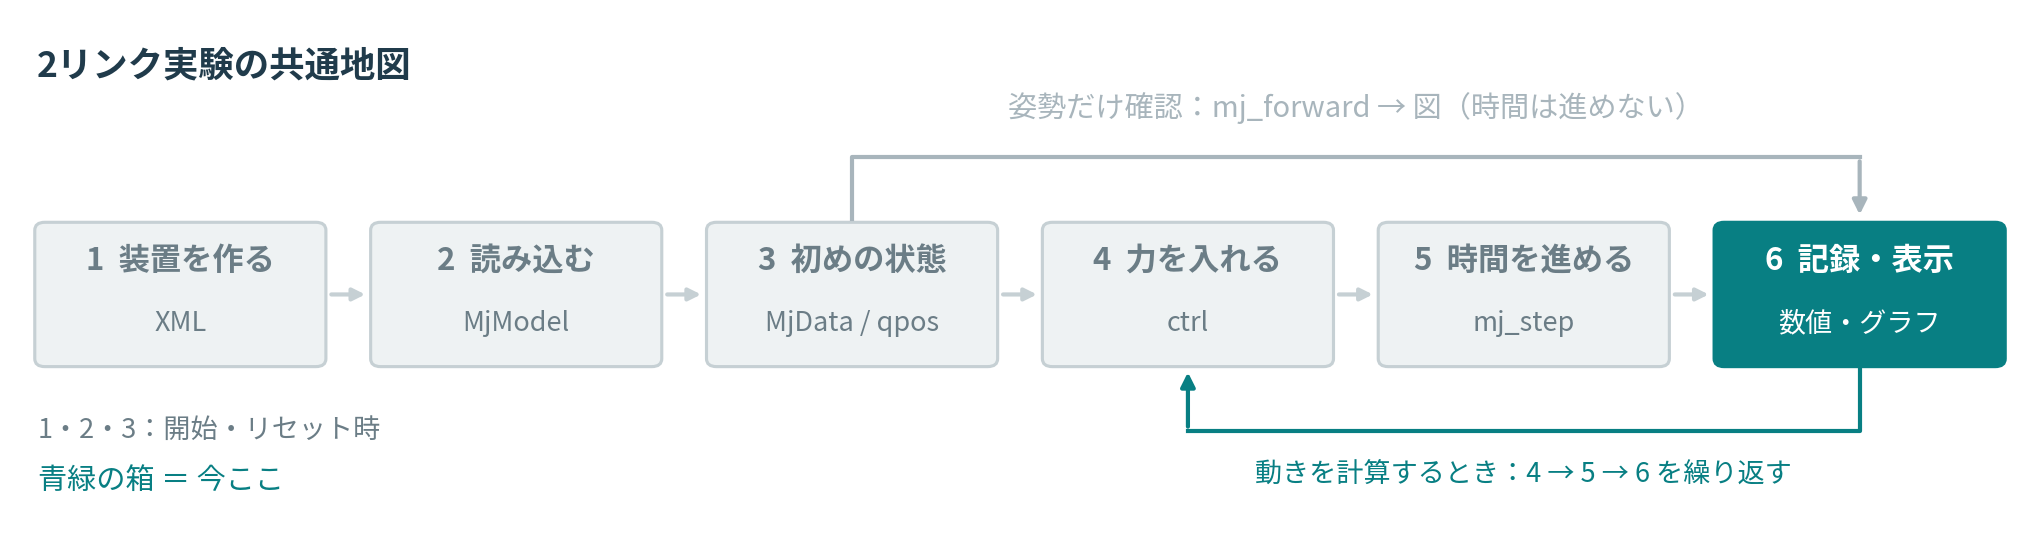

**今すること：** 先ほどの一歩で何が変わったか、数値で確認する。

**回答：** 時刻は＿＿秒。肩・肘の角速度は＿＿。予想との違い：＿＿

In [20]:
print("時刻:", drive_example.time)
print("角度 [rad]:", drive_example.qpos, "角速度 [rad/s]:", drive_example.qvel)

時刻: 0.002
角度 [rad]: [ 1.92792873e-05 -5.31859680e-05] 角速度 [rad/s]: [ 0.00963964 -0.02659298]


### M6.7｜④⑤⑥をつなぎ、1秒間繰り返す

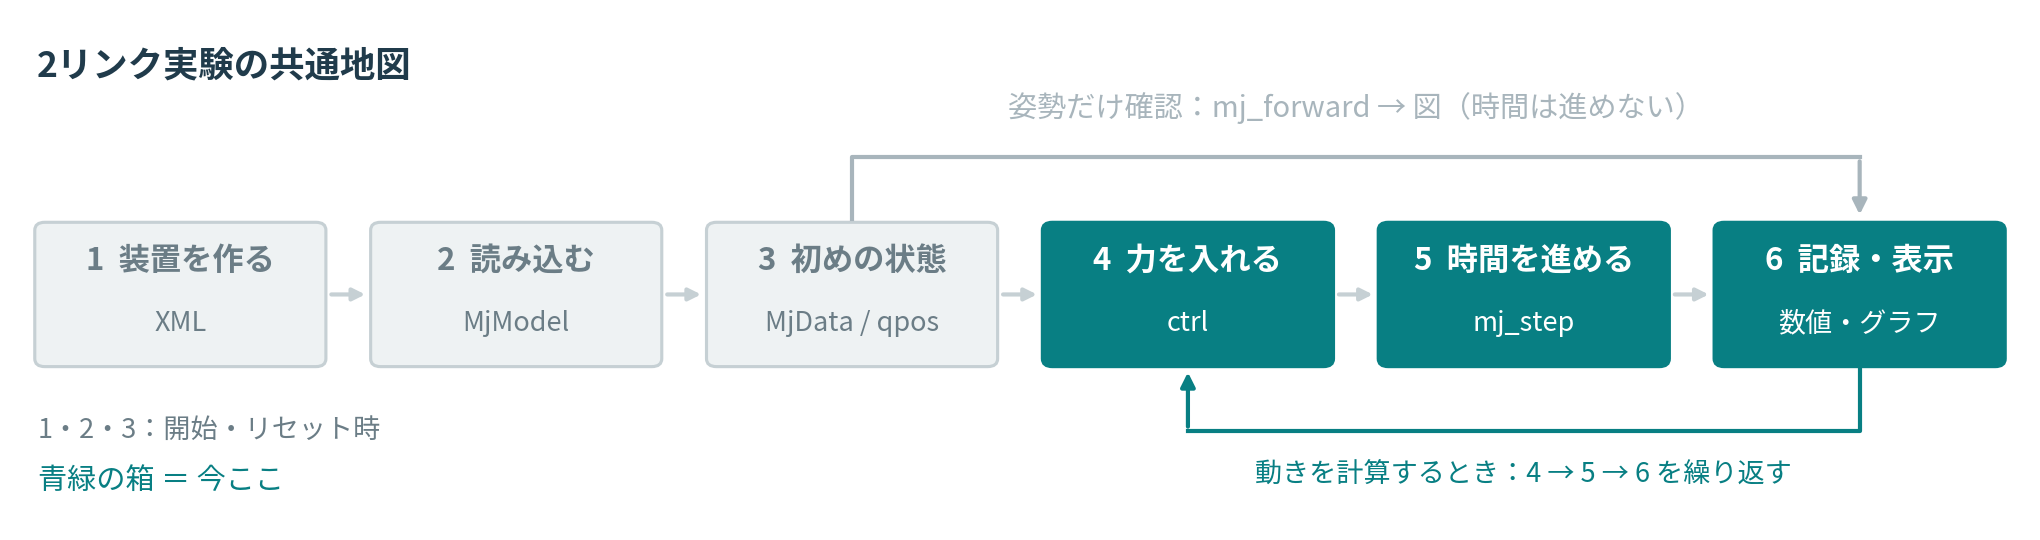

ここまでの短い行を、繰り返しにまとめます。**自分で書くM6は3か所**です。

1. `u = None`：0.20秒未満は `torque`、その後は0.0。書式は `a if 条件 else b`。
2. `pass`：肩へu、肘へ0を入れる行（④）。
3. その下：一歩進める行（⑤）。

`rows.append` が⑥の記録。初期状態も記録するため、各周の先頭に置いています。一歩進めた後の状態は次の周に記録し、最後は1秒で終えます。

In [21]:
def drive_arm(model, torque):
    d = mujoco.MjData(model)
    rows = []
    for i in range(501):
        u = None  # TODO: 0.20秒未満だけtorqueを入力
        if u is None: return None
        rows.append([d.time, *d.qpos.copy(), *d.qvel.copy(), u])
        if i < 500:
            pass  # TODO: ctrlへの代入とmj_step（2行）
    return pd.DataFrame(rows, columns=["time_s","q1","q2","dq1","dq2","u"])

### M6.8｜⑥ グラフで、入力と動きを比べる

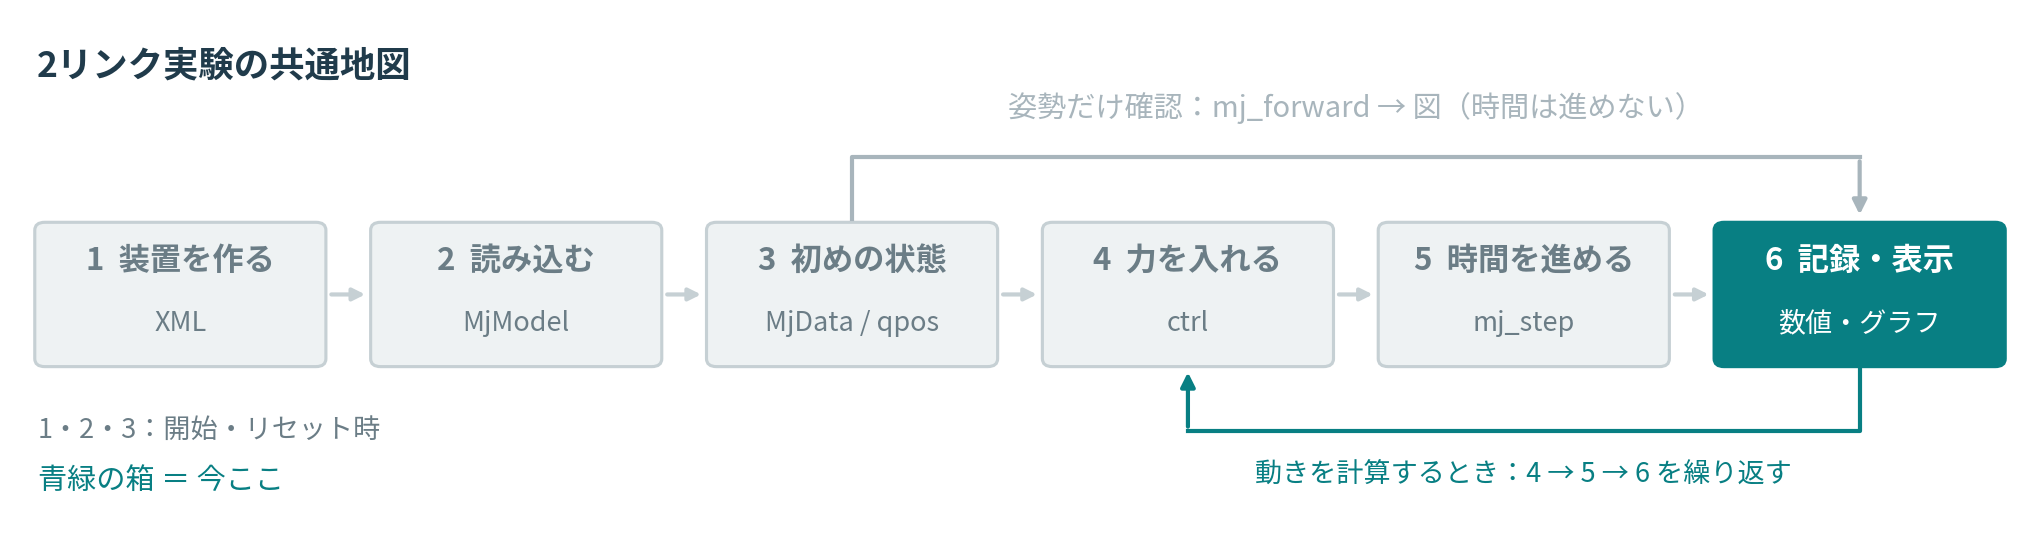

確認道具を実行し、入力0の例と、0.20秒だけ入力する例を比べます。

**見る場所：** 入力が0になった後の角速度。すぐ0になるか、0.20秒と0.30秒で確かめます。
表の `q1,q2` は角度、`dq1,dq2` は角速度、`u` は肩の入力です。

In [22]:
#@title 入力課題の確認とグラフの道具
def check_drive(fn, verbose=True):
    try:
        log = fn(drive_model, .2)
        zero = fn(drive_model, 0.)
        if log is None or zero is None: raise ValueError("入力とstepを補完してください")
        times = np.arange(501) * .002
        expected_u = np.where(times < .2 - 1e-10, .2, 0.)
        ok = (len(log) == 501 and np.allclose(log.time_s, times)
              and np.allclose(log.u, expected_u)
              and np.isfinite(log.to_numpy()).all()
              and log.q1.abs().max() > .01 and log.dq2.abs().max() > .01
              and np.allclose(zero[["q1","q2","dq1","dq2"]], 0))
        # Evaluate a few state samples against a fresh MuJoCo trajectory.
        ref = mujoco.MjData(drive_model)
        for i in range(501):
            if i in [1, 99, 101, 300, 500]:
                ok = ok and np.allclose(log.iloc[i][["q1","q2","dq1","dq2"]], np.r_[ref.qpos,ref.qvel])
            if i < 500:
                ref.ctrl[:] = [.2 if ref.time < .2 else 0., 0.]
                mujoco.mj_step(drive_model, ref)
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M6 コード確認:", "PASS" if ok else "未完成／再確認（入力・時間・状態を確認）")
    return bool(ok)

drive_ready = check_drive(drive_arm)
arm_zero, arm_pulse = None, None
if drive_ready:
    arm_zero = drive_arm(drive_model, 0.)
    arm_pulse = drive_arm(drive_model, .2)
    fig, axes = plt.subplots(3, 1, figsize=(7, 7), sharex=True, layout="constrained")
    axes[0].plot(arm_pulse.time_s, np.rad2deg(arm_pulse.q1), label="Shoulder")
    axes[0].plot(arm_pulse.time_s, np.rad2deg(arm_pulse.q2), label="Elbow")
    axes[0].plot(arm_zero.time_s, arm_zero.q1, "--", label="Zero input")
    axes[0].set_ylabel("Angle [deg]"); axes[0].legend()
    axes[1].plot(arm_pulse.time_s, arm_pulse.dq1); axes[1].set_ylabel("Shoulder [rad/s]")
    axes[2].plot(arm_pulse.time_s, arm_pulse.u); axes[2].set(xlabel="Time [s]", ylabel="Torque [N m]")
    fig.savefig(WORK/"arm_input.png"); plt.show()
    display(arm_pulse.iloc[[0, 100, 150, 500]])

ValueError 入力とstepを補完してください
M6 コード確認: 未完成／再確認（入力・時間・状態を確認）


### M6.9｜⑥ 記録を順番に描いて、動画にする

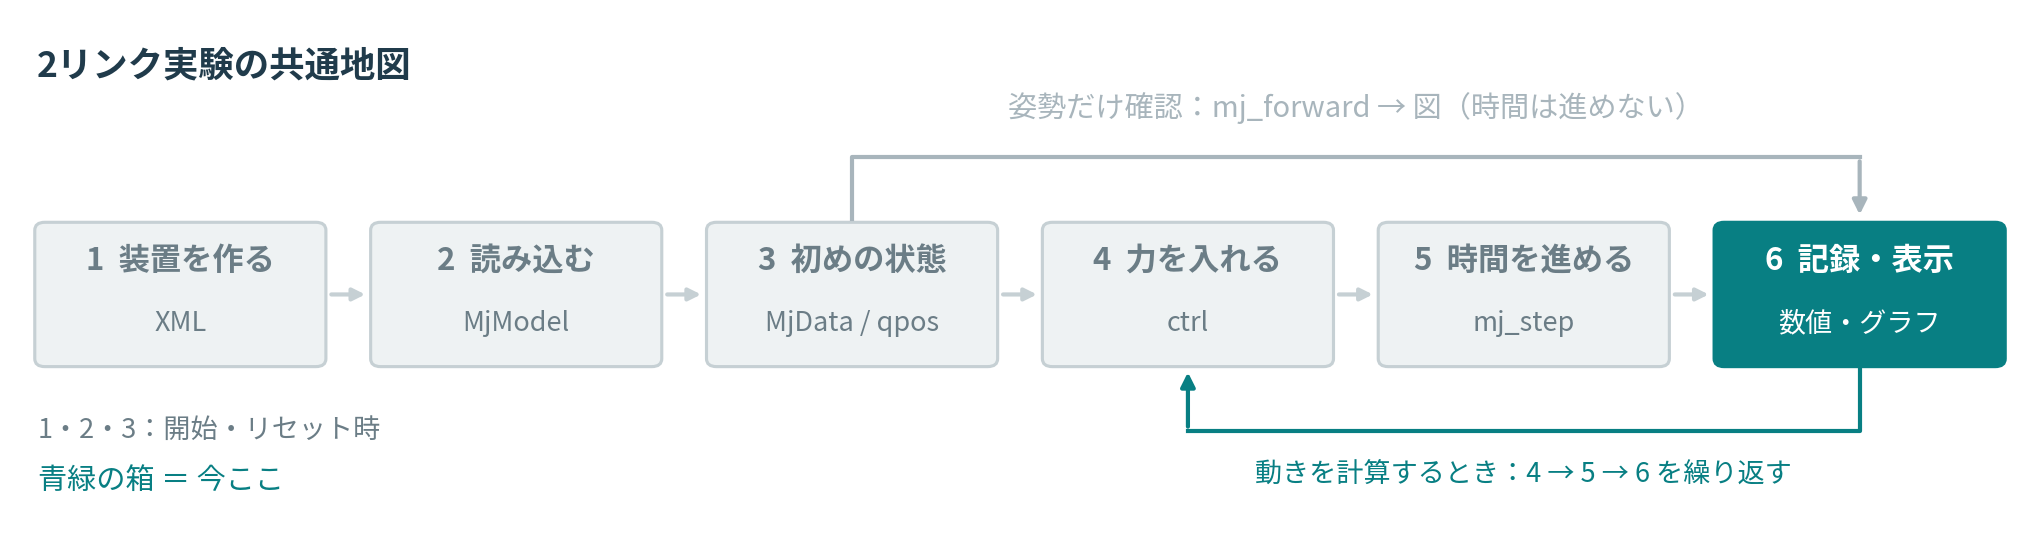

次の道具は**計算済みの角度の記録**を受け取り、順に描きます。動画を再生するときに新たな運動を計算しているわけではありません。

**確認：** 肘の入力は0でも動いた？ グラフと動画を比べます。

In [23]:
if drive_ready:
    display(render_qpos_log(DRIVE_XML, arm_pulse[["q1","q2"]].to_numpy(),
                           "arm_input", [.35,.18,.1], 1.7, elevation=-65))
else:
    print("M6を完成後に入力による運動を再生します。")

M6を完成後に入力による運動を再生します。


### M6の回答｜プログラムの各行を地図に戻す

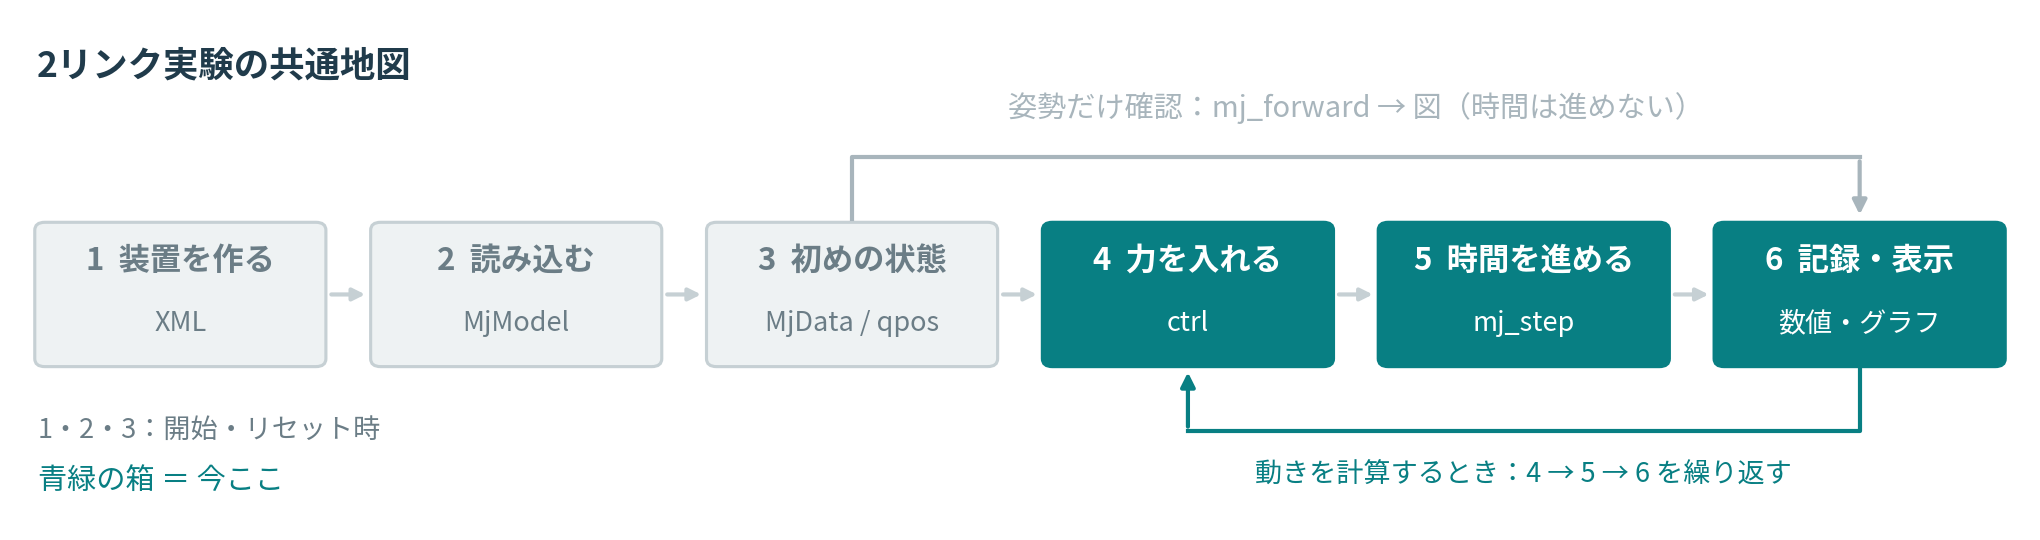

1. `ctrl`、`mj_step`、`rows.append` はそれぞれ何番の箱ですか。
2. 入力を0にすると速度もすぐ0ですか。0.20秒と0.30秒の値を使って答えます。

**行と役割：** ＿＿　**数値と理由：** ＿＿

肘が動くのは2本の棒が力学的につながっているためです。今回は水平アームなので、重力は回転軸まわりに回しません。縦のアームも同じとは限りません。

**M5とM6の違い：** 自分で指定したのは「姿勢」か「入力」か。＿＿

## M7｜同じ部品で倒立振子を読む
**到達点：** slide＋hinge、状態と入力の並び、実験の停止条件を説明する。

### M7.1｜台車の子として振子を置く
台車はx方向に動くslide、棒はy軸まわりのhingeです。bodyを入れ子にする考え方はM5と同じです。棒のgeomを原点から**上向き**に作るので、角度0 radが直立です。
最初にこの構造の骨組みを読みます。`...`はここでは説明用の省略です。実行用モデルは次の道具にあります。

```xml
<body name="cart">
  <joint name="cart_slide" type="slide" axis="1 0 0"/>
  <body name="pole">
    <joint name="pole_hinge" type="hinge" axis="0 1 0"/>
    <geom type="capsule" fromto="0 0 0 0 0 1" .../>
  </body>
</body>
```

台車にだけmotorを付けます。このgear=1のslide motorの入力は範囲内で力[N]です。

In [24]:
#@title 倒立振子の寸法・質量を含むモデル
CART_XML = """<mujoco model="lesson03_cartpole">
  <option timestep="0.002" gravity="0 0 -9.81" integrator="RK4"/>
  <worldbody>
    <light pos="0 -3 4"/>
    <geom type="plane" size="5 3 0.1" rgba="0.85 0.86 0.84 1" contype="0" conaffinity="0"/>
    <body name="cart" pos="0 0 0.15">
      <joint name="cart_slide" type="slide" axis="1 0 0" damping="0.05"/>
      <geom type="box" size="0.15 0.1 0.075" mass="1" rgba="0.14 0.49 0.48 1" contype="0" conaffinity="0"/>
      <body name="pole" pos="0 0 0.075">
        <joint name="pole_hinge" type="hinge" axis="0 1 0" damping="0.002"/>
        <geom type="capsule" fromto="0 0 0 0 0 1" size="0.015" mass="0.1" rgba="0.78 0.39 0.24 1" contype="0" conaffinity="0"/>
      </body>
    </body>
  </worldbody>
  <actuator><motor joint="cart_slide" gear="1" ctrllimited="true" ctrlrange="-10 10"/></actuator>
</mujoco>"""

cart_model = mujoco.MjModel.from_xml_string(CART_XML)
print("nq, nv, nu =", cart_model.nq, cart_model.nv, cart_model.nu)

nq, nv, nu = 2 2 1


### M7.2｜状態の並びを取り違えない
|配列|0番|1番|
|---|---|---|
|`qpos`|台車位置x [m]|棒の角度θ [rad]|
|`qvel`|台車速度v [m/s]|棒の角速度ω [rad/s]|
|`ctrl`|台車への力 [N]|なし|

**課題M7a：** 表を見て、`[x,v,theta,omega]`の順に4つの値を返す関数にします。
`np.r_[d.qpos, d.qvel]`をそのまま使うと`[x,theta,v,omega]`になる点に注意します。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [25]:
def read_cart_state(d):
    return None  # TODO: np.array([...])で4つの成分を指定

### M7.3｜入力と停止条件を実装する
**課題M7b：** `cart_input`は0.10秒未満だけ指定した力を返します。M6と同じ条件式です。
`outside_range`は、角度が±60°以上 **または** 台車位置が±2.4 m以上なら`True`を返します。絶対値は`abs`、論理和は`or`です。
この停止は実験の評価範囲を決めるためです。壁への衝突を表しません。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [26]:
def cart_input(time_s, force_N):
    return None  # TODO: 時刻によって入力を切り替える

def outside_range(state):
    x, v, theta, omega = state
    return None  # TODO: 角度または位置が範囲外か判定

### M7.4｜入力 → step → 状態を読む
次のループはこれまでと同じです。学生が実装した3関数を使い、初期角度5°と10°、入力あり・なしを比較します。
停止理由が`duration`なら1.2秒の記録を終えた意味です。これだけで安定制御が成功したとは言えません。

In [27]:
#@title 状態・入力・停止判定の確認道具
def check_cart(reader, policy, stop, verbose=True):
    try:
        d = mujoco.MjData(cart_model)
        d.qpos[:] = [.12, .23]; d.qvel[:] = [.34, .45]
        value = reader(d)
        ok = value is not None and np.asarray(value).shape == (4,) and np.allclose(value, [.12,.34,.23,.45])
        ok = ok and all(policy(t, f) == (f if t < .1 else 0.) for t in [0.,.099,.1,.2] for f in [-1.,0.,1.])
        cases = [([0,0,0,0],False), ([2.4,0,0,0],True), ([-2.4,0,0,0],True),
                 ([0,0,np.deg2rad(60),0],True), ([0,0,-np.deg2rad(60),0],True),
                 ([2.39,0,np.deg2rad(59),0],False), ([0,99,0,99],False)]
        ok = ok and all(stop(np.array(s)) == expected for s,expected in cases)
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M7 コード確認:", "PASS" if ok else "未完成／再確認（順序・単位・境界を確認）")
    return bool(ok)
cart_ready = check_cart(read_cart_state, cart_input, outside_range)

M7 コード確認: 未完成／再確認（順序・単位・境界を確認）


In [28]:
def run_cart(initial_deg=5., force_N=0.):
    d = mujoco.MjData(cart_model)
    d.qpos[1] = np.deg2rad(initial_deg)
    rows, reason = [], "duration"
    for i in range(601):
        state = read_cart_state(d)
        u = cart_input(d.time, force_N)
        rows.append([d.time, *state, u])
        if outside_range(state):
            reason = "evaluation_limit"; break
        if i < 600:
            d.ctrl[0] = u
            mujoco.mj_step(cart_model, d)
    return pd.DataFrame(rows, columns=["time_s","x","v","theta","omega","u"]), reason

In [29]:
#@title 倒立振子の比較表示
cart_results = {}
if cart_ready:
    fig, axes = plt.subplots(3, 1, figsize=(7,7), sharex=True, layout="constrained")
    for name, angle, force in [("5 deg / 0 N",5,0), ("10 deg / 0 N",10,0), ("5 deg / pulse",5,1)]:
        table, reason = run_cart(angle, force)
        cart_results[name] = (table, reason)
        print(name, "終了時刻:", table.time_s.iloc[-1], "理由:", reason)
        axes[0].plot(table.time_s, np.rad2deg(table.theta), label=name)
        axes[1].plot(table.time_s, table.x)
        axes[2].plot(table.time_s, table.u)
    axes[0].set_ylabel("Angle [deg]"); axes[0].legend()
    axes[1].set_ylabel("Cart x [m]")
    axes[2].set(xlabel="Time [s]", ylabel="Input [N]")
    fig.savefig(WORK/"cart_compare.png"); plt.show()
    cart_table = cart_results["5 deg / 0 N"][0]
    display(render_qpos_log(CART_XML, cart_table[["x","theta"]].to_numpy(),
                           "cartpole", [0,0,.6], 3., elevation=-15))
else:
    print("M7a/bを完成後、確認・比較を再実行します。")

M7a/bを完成後、確認・比較を再実行します。


### 記録 M7｜自分の言葉で説明
5°を`qpos[1]=5`と書くと、何が違いますか。
各実験の初期条件・入力・終了時刻・停止理由を書いてください。初期角度が違う実験を比べるとき、入力の影響だけを比べたことになりますか。
0.1秒の押し入力だけで「倒立振子を安定に保つ制御を作った」と言えるでしょうか。そう判断するために、今の記録に加えて何を確認する必要がありますか。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## ロボット篇の課題｜翌週のPPT発表を準備する
記録M5〜M7、自作コードと試行結果を使って、次の点を説明します。

- **装置と姿勢：** 2本の棒と関節はXMLのどこに対応するか。肘の角度は何を基準に測るか。
- **流れと動力学：** 自分のコードは流れ図のどこか。`qpos`の指定と`mj_forward`だけの場合と、`ctrl`を入れて`mj_step`する場合では、何が違うか。
- **根拠と次の問題：** 無入力と肩への入力で角度・速度がどう変わったか。倒立振子では初期角度や入力を変えると何が起き、どの条件で実験を止めたか。

**到達位置：** ＿＿　**残っている課題：** ＿＿

### 翌週のPPT発表の組み立て
課題の報告は**翌週の授業でのPPT発表**です。担当者が指定した範囲について、Notebookの回答を発表にまとめます。**ZIP・CSV・Notebookの提出は不要です。**

**PPTは全体で4〜5枚が目安。** 小球篇とロボット篇の両方を発表する場合も、1つの発表にまとめます。

1. **何を確かめたか：** 装置の図、実験条件、実行前の予想。
2. **どのように実装したか：** 自分で書いた重要な3〜8行と、その行の役割。ロボット篇では流れ図の場所も示す。
3. **何が起きたか：** 比較する図・表・短い動画。軸・単位・条件を付け、数値を1つ以上示す。
4. **なぜそうなったか：** 予想との一致・違い、その理由。上の確認質問にも答える。
5. **まだ分からないこと：** 必要なら1枚追加。試した変更、失敗、次に確認すること。

全課題に取り組み、回答は自分のNotebookに残します。発表では各セルを読み上げず、重要な比較と自作コードを使って説明します。未完成の課題も、どこまでできたか・何を試したか・どこで困ったかを示します。

**質疑で確認すること：** 「なぜこの行が必要？」「どの数値が説明の根拠？」「条件を変えるとどうなる？」。AIに相談したコードも、自分の言葉で説明してください。コードのPASSは理解度の採点ではありません。

### 自分用の記録を残す
回答と実行結果を含むNotebookを自分のGoogle Driveへ保存し、発表に使う図・表・コードをPPTへ貼り付けます。下のセルは自己確認と一時ファイルの保存用です。ZIPは作りません。Colabの実行環境内にあるCSV・XMLはDriveのNotebookに自動添付されないため、再実験で必要なものだけファイル欄から自分用に保存してください。

In [30]:
#@title 発表前の自己確認と実験記録（2リンク篇）
statuses = {
    'M5_arm':check_arm(arm_model,set_arm_pose,verbose=False),
    'M6_input':check_drive(drive_arm,verbose=False),
    'M7_cart':check_cart(read_cart_state,cart_input,outside_range,verbose=False)}
statuses['M5_target'] = False
if statuses['M5_arm']:
    tip = arm_points(set_arm_pose(arm_model,target_q1,target_q2))[-1,:2]
    statuses['M5_target'] = bool(np.linalg.norm(tip-[.45,.60]) <= .04)
for name in ['arm_motion.csv','cart_0.csv','cart_1.csv','cart_2.csv']:
    (WORK/name).unlink(missing_ok=True)
if statuses['M6_input']:
    drive_arm(drive_model,.2).to_csv(WORK/'arm_motion.csv',index=False)
if statuses['M7_cart']:
    for i,(angle,force) in enumerate([(5,0),(10,0),(5,1)]):
        table,reason=run_cart(angle,force)
        table.to_csv(WORK/f'cart_{i}.csv',index=False)
for filename,xml in [('student_arm.xml',ARM_POSE_XML),('drive_arm.xml',DRIVE_XML),('cartpole.xml',CART_XML)]:
    (WORK/filename).write_text(xml,encoding='utf-8')
for valid,prefix in [(statuses['M5_arm'],'arm_pose'),(statuses['M5_target'],'arm_target'),
                     (statuses['M6_input'],'arm_input'),(statuses['M7_cart'],'cart')]:
    if not valid:
        for path in WORK.glob(prefix+'*'):
            if path.suffix in ['.png','.html']:path.unlink()
environment = {'lesson':'03B-two-link-v10-split','python':sys.version.split()[0],
    'mujoco':mujoco.__version__,'colab':IN_COLAB,'rendering':os.environ.get('MUJOCO_GL'),
    'code_checks':statuses,'written_answers':'NOT_AUTO_GRADED: M5-M7',
    'figures':'Snapshots: rerun display cells after changing conditions'}
(WORK/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
print('2リンク篇のコード確認:',statuses)
print('実験記録の一時フォルダ:',WORK)
print('課題は翌週のPPT発表で説明します。ZIPの提出は不要です。')
print('回答と実行結果入りNotebookを自分のDriveへ保存し、発表に使う図・表・コードをPPTへ貼り付けてください。')
print('このフォルダのCSV・XMLは実行環境内の一時ファイルです。必要なものはファイル欄から自分用に保存してください。')

2リンク篇のコード確認: {'M5_arm': False, 'M6_input': False, 'M7_cart': False, 'M5_target': False}
実験記録の一時フォルダ: /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/robot-student/b3_lesson03B_2link
課題は翌週のPPT発表で説明します。ZIPの提出は不要です。
回答と実行結果入りNotebookを自分のDriveへ保存し、発表に使う図・表・コードをPPTへ貼り付けてください。
このフォルダのCSV・XMLは実行環境内の一時ファイルです。必要なものはファイル欄から自分用に保存してください。


## 参照資料
用語と動作は配布環境のMuJoCo 3.3.3で確認します。

- [MuJoCo Overview：モデル・データ・動力学](https://mujoco.readthedocs.io/en/3.3.3/overview.html)
- [Modeling：親子構造と座標](https://mujoco.readthedocs.io/en/3.3.3/modeling.html#kinematic-tree)
- [XML reference：joint](https://mujoco.readthedocs.io/en/3.3.3/XMLreference.html#body-joint)
- [Simulation：forwardとstep](https://mujoco.readthedocs.io/en/3.3.3/programming/simulation.html)
- [Computation：積分・接触・入力](https://mujoco.readthedocs.io/en/3.3.3/computation/index.html)

導入の出典付き画像は前版から保持しています。数値図・動画はこのNotebookの計算結果です。